# **<font color="#5c5bdf">Trabajo Práctico Integrador</font>**

# Dataset: <font color="DFFF4F">Tenis Tournaments & Player Stadistics</font>

##**Grupo N° 4**
### Integrantes
* Angonese, Juan Pablo - 98230.
* Ceballos Pratto, Agustín José - 93203.
* Ghibaudo, Alan Yair - 97570.
* Scrosati, Emanuel Genaro - 95632.
* Villegas, Genaro - 91541.
* Wendler, Juan José - 89390.


# **Fase de Extracción (EXTRACT)**
Obtenemos los datos iniciales desde la URL indicada en el código. A su vez también delimitamos el periodo de tiempo desde el cual realizaremos el trabajo práctico `[2000 - 2026]`.

In [1]:
import pandas as pd

base_url = 'https://raw.githubusercontent.com/Tennismylife/TML-Database/master'

# Desde donde partimos el análisis de los datos
ANIO_INICIO = 2000
ANIO_FIN = 2026

# Contadores iniciales
total_filas = 0
archivos_descargados = 0

lista_dfs = []

for anio in range(ANIO_INICIO, ANIO_FIN + 1):
  nom_arch = f'{anio}.csv'
  url_arch = f'{base_url}/{nom_arch}'

  try:
    df_anio = pd.read_csv(url_arch)
    lista_dfs.append(df_anio)

    filas = len(df_anio)
    total_filas += filas
    archivos_descargados += 1
    print(f'Año {anio} procesado: {filas} registros cargados.')

  except Exception as e:
    print(f'No se pudo descargar el año {anio}: {e}')

# Acá unimos todos los datasets, formando un dataset que abarque el periodo de torneos desde los 2000-2026 en uno solo.
if lista_dfs:
    df_torneos = pd.concat(lista_dfs, ignore_index=True)
    print(f'\nResumen: {archivos_descargados} archivos descargados.')
    print(f'Total de filas procesadas: {total_filas}')
    print(f'Forma del DataFrame final: {df_torneos.shape}')
else:
    print("\nNo se pudo descargar ningún archivo.")

Año 2000 procesado: 3378 registros cargados.
Año 2001 procesado: 3311 registros cargados.
Año 2002 procesado: 3213 registros cargados.
Año 2003 procesado: 3218 registros cargados.
Año 2004 procesado: 3288 registros cargados.
Año 2005 procesado: 3263 registros cargados.
Año 2006 procesado: 3267 registros cargados.
Año 2007 procesado: 3192 registros cargados.
Año 2008 procesado: 3123 registros cargados.
Año 2009 procesado: 3085 registros cargados.
Año 2010 procesado: 3030 registros cargados.
Año 2011 procesado: 3015 registros cargados.
Año 2012 procesado: 3009 registros cargados.
Año 2013 procesado: 2944 registros cargados.
Año 2014 procesado: 2901 registros cargados.
Año 2015 procesado: 2945 registros cargados.
Año 2016 procesado: 2970 registros cargados.
Año 2017 procesado: 2936 registros cargados.
Año 2018 procesado: 2926 registros cargados.
Año 2019 procesado: 2806 registros cargados.
Año 2020 procesado: 1466 registros cargados.
Año 2021 procesado: 2735 registros cargados.
Año 2022 p

In [2]:
import pandas as pd

url_jugadores = 'https://raw.githubusercontent.com/Tennismylife/TML-Database/master/ATP_Database.csv'

try:
    # Descarga directa del archivo en memoria
    df_players = pd.read_csv(url_jugadores, encoding='latin1')

    # Métricas y confirmación de carga
    filas = len(df_players)
    print(f'Archivo de jugadores cargado exitosamente.')
    print(f'Total de registros cargados: {filas}')
    print(f'Forma del DataFrame final: {df_players.shape}')

except Exception as e:
    print(f'No se pudo descargar el archivo de jugadores: {e}')
    df_players = None

Archivo de jugadores cargado exitosamente.
Total de registros cargados: 7643
Forma del DataFrame final: (7643, 12)


## **Valor nulos iniciales**
Al obtener los datos iniciales de nuestro dataset, mediante el uso de *isna()* y *sum()* corroboramos la cantidad de valores nulos que tenemos por columna.

In [3]:
print(df_torneos.isna().sum())

tourney_id                0
tourney_name              0
surface                 143
draw_size                43
tourney_level             0
indoor                 6875
tourney_date              0
match_num               489
winner_id                 0
winner_seed           45792
winner_entry          68401
winner_name               0
winner_hand             663
winner_ht              1534
winner_ioc                2
winner_age               68
winner_rank             633
winner_rank_points      633
loser_id                  1
loser_seed            60172
loser_entry           62466
loser_name                0
loser_hand             1556
loser_ht               3031
loser_ioc                11
loser_age               227
loser_rank             1573
loser_rank_points      1573
score                     2
best_of                   0
round                     0
minutes                7238
w_ace                  6422
w_df                   6422
w_svpt                 6422
w_1stIn             

In [4]:
print(df_players.isna().sum())

id               0
player           0
atpname          0
birthdate     2882
weight        4802
height        4839
turnedpro     6054
birthplace    4403
coaches       6227
hand          2767
backhand      6190
ioc             90
dtype: int64


# **Fase de Transformación (TRANSFORM)**

En esta etapa realizaremos la limpieza y transformación de los datasets iniciales (players y torneos) utilizando criterios estadísticos y decisiones de dominio de negocio, otorgando asi un resultado de ambos datasets limpios y en el formato necesario para su posterior uso.

In [5]:
import pandas as pd
import numpy as np

df_players_clean = df_players.copy()

# Estandarización
if 'coaches' in df_players_clean.columns:
    df_players_clean['coaches'] = df_players_clean['coaches'].fillna('Solo')

# Filtrado de columnas esenciales para el dominio del problema
columnas_deseadas = ['id', 'player', 'birthdate', 'atpname', 'height', 'hand', 'coaches', 'ioc']
df_players_clean = df_players_clean[[col for col in columnas_deseadas if col in df_players_clean.columns]]

# Renombre de columna.
if 'height' in df_players_clean.columns:
    df_players_clean = df_players_clean.rename(columns={'height': 'ht'})

# Parsear la fecha de nacimiento en formato YYYY:MM:DD
if 'birthdate' in df_players_clean.columns:
    fechas_string = df_players_clean['birthdate'].astype(str).str.split('.').str[0]
    df_players_clean['birthdate'] = pd.to_datetime(fechas_string, format='%Y%m%d', errors='coerce')

# Obtener IDs de jugadores que registran actividad en torneos generales
ids_ganadores = set(df_torneos['winner_id'].astype(str).unique())
ids_perdedores = set(df_torneos['loser_id'].astype(str).unique())
ids_activos = ids_ganadores.union(ids_perdedores)

# Obtenemos los jugadores activos dentro de nuestro dataset.
df_players_clean['id'] = df_players_clean['id'].astype(str)
df_players_clean = df_players_clean[df_players_clean['id'].isin(ids_activos)].reset_index(drop=True)

# Transformar aquellos valores nulos con la mediana de las alturas.
mediana_altura_jugadores = df_players_clean['ht'].median()
df_players_clean['ht'] = df_players_clean['ht'].fillna(mediana_altura_jugadores)

# Categoría neutra 'U' (Unknown) para jugadores de los que se desconoce su mano habil.
df_players_clean['hand'] = df_players_clean['hand'].fillna('U')

### **Análisis de Valores Nulos y Outliers con Boxplots**

Antes de decidir cómo imputar los datos faltantes de las variables continuas:

* `winner_age`
* `loser_age`
* `winner_ht`
* `loser_ht`
* `minutes`

Analizamos su distribución y la presencia de outliers mediante gráficos de caja (*Boxplots*).
* **Edades y Alturas:** Presentan distribuciones simétricas y estables, por lo que vamos a usar la **mediana** para no alterar la tendencia central de los valores observados para esta.
* **Duración en Minutos (`minutes`):** Tienen una fuerte asimetría hacia la derecha debido a partidos inusualmente largos (valor atípico). Entonces vamos a utilizar la **mediana agrupada por el formato de sets (Columna: `best_of`)** para tener una mayor precisión teniendo en cuenta el formato de los partidos.

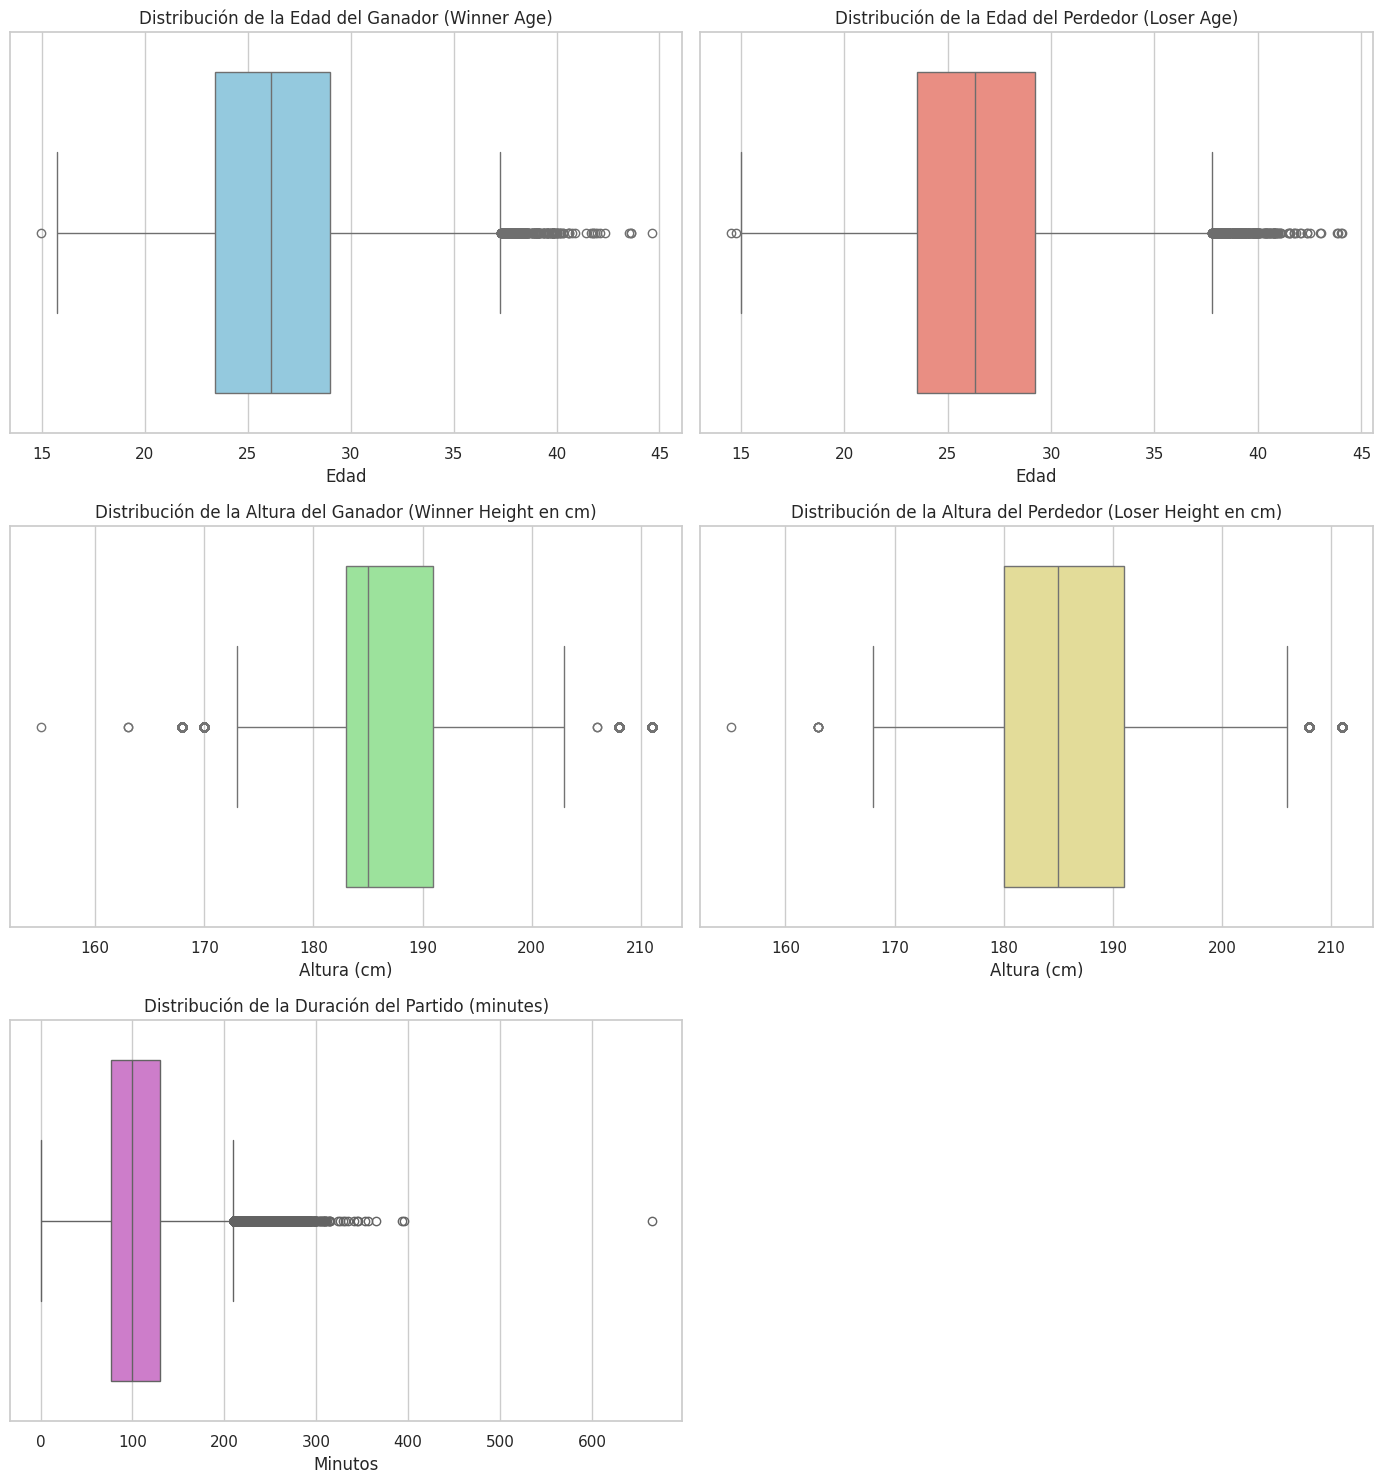

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 15))

# Gráficos de las Edades
sns.boxplot(ax=axes[0, 0], x=df_torneos['winner_age'], color='skyblue')
axes[0, 0].set_title('Distribución de la Edad del Ganador (Winner Age)')
axes[0, 0].set_xlabel('Edad')

sns.boxplot(ax=axes[0, 1], x=df_torneos['loser_age'], color='salmon')
axes[0, 1].set_title('Distribución de la Edad del Perdedor (Loser Age)')
axes[0, 1].set_xlabel('Edad')

# Gráficos de las Alturas
sns.boxplot(ax=axes[1, 0], x=df_torneos['winner_ht'], color='lightgreen')
axes[1, 0].set_title('Distribución de la Altura del Ganador (Winner Height en cm)')
axes[1, 0].set_xlabel('Altura (cm)')

sns.boxplot(ax=axes[1, 1], x=df_torneos['loser_ht'], color='khaki')
axes[1, 1].set_title('Distribución de la Altura del Perdedor (Loser Height en cm)')
axes[1, 1].set_xlabel('Altura (cm)')

# Gráfico de la duración de los partidos
sns.boxplot(ax=axes[2, 0], x=df_torneos['minutes'], color='orchid')
axes[2, 0].set_title('Distribución de la Duración del Partido (minutes)')
axes[2, 0].set_xlabel('Minutos')

axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

### **Justificación de Imputaciones según la Distribución:**
* **Edades y Alturas:** Tienen distribuciones bastante simétricas y estables. Por lo que utilizando la mediana no alterariamos la tendencia central.
* **Duración en Minutos (`minutes`):** Tiene bastante asimetría positiva hacia la derecha (outliers de partidos extremadamente largos). Por lo que hacer uso de la  media sesgaría los datos.
Por lo que entonces utilizaremos la **mediana agrupada por el formato de sets (`best_of`)** es el método más preciso para representar esto.

### **Análisis de Nulos por Nivel de Torneo**
Tras observar varios de los archivos que componen nuestro dataset, y realizar un reconocimiento del negocio, observamos que los partidos de ***Copa Davis*** y los ***Juegos Olimpicos*** presentan una gran cantidad de datos faltantes en sus estadísticas de juego.

Para ello evaluamos la proporción de estadísticas de partido faltantes según el nivel del torneo/categoría `tourney_level` para justificar decisiones de negocio y excluír ciertos eventos.

In [7]:
# Identificamos partidos que no cuentan con estadísticas de rendimiento
partidos_sin_estadisticas = df_torneos[df_torneos['w_ace'].isna()]

# Porcentaje de nulos por torneo
cont_nulos_nivel = partidos_sin_estadisticas['tourney_level'].value_counts()
cont_total_nivel = df_torneos['tourney_level'].value_counts()
porcentaje_nulos_nivel = (cont_nulos_nivel / cont_total_nivel) * 100

# Tabla
resumen_calidad = pd.DataFrame({
    'Partidos Totales': cont_total_nivel,
    'Partidos Sin Stats': cont_nulos_nivel.fillna(0).astype(int),
    'Porcentaje de Nulos (%)': porcentaje_nulos_nivel.fillna(0)
})

print("Análisis de calidad de estadísticas por nivel de torneo:")
display(resumen_calidad.round(2).sort_values(by='Porcentaje de Nulos (%)', ascending=False))

Análisis de calidad de estadísticas por nivel de torneo:


,Partidos Totales,Partidos Sin Stats,Porcentaje de Nulos (%)
tourney_level,,,
D,7331,5871,80.08
O,448,259,57.81
A,855,77,9.01
F,406,31,7.64
250,30818,99,0.32
500,10378,27,0.26
M,14774,39,0.26
G,13081,19,0.15


**Decisión de Negocio:**
* **Copa Davis (`D`):** Estos torneos tienen un **80.08%** de nulos en las estadísticas.
* **Juegos Olímpicos (`O`):** Estos torneos tienen un **57.81%** de nulos.

Para mantener consistencia con el modelo decidimos eliminar estos torneos de nuestro dataset, ya que no proveen estadísticas y a su vez su valores no representan ser un torneo significativo para hacer uso de estos datos, también debemos tener en cuenta que para estos torneos se juega de forma diferente a cualquier torneo ATP.


### **Pipeline de Transformación Consolidado (`df_torneos_clean`)**

Vamos a realizar secuencialmente el proceso de transformación evaluado para obtener el dataset limpio y listo para la ingeniería de características, incluyendo cuestiones como:

**Inicialmente:** Copiaremos el dataset inicial, lo que nos permitira trabajar sin alterar los datos de inicio.
* Resolución de manos con la categoría neutra `'U'` (Unknown).
* Solución secuencial de `match_num`.
* Transformación de fechas y variables a su formato y tipo de dato ideal.
* Descarte de **registros** y **columnas** que no aportan valor al dataset final.
* Completar valores faltantes, haciendo uso de medias, medianas y modas.
* Estructuración de Score: Esto parte de que teniamos los resultados de cada set (que dependian de `best_of` para la cantidad de sets), creando nuevas columnas, aplicando Ing. de Características.
* Uso de codificación One-Hot: Permitiendo que en posteriores etapas nuestro modelo de ML no asuma de forma erronea una especie de orden numérico impuesto arbitrariamente.

In [8]:
import pandas as pd
import numpy as np
import re

df_torneos_clean = df_torneos.copy()

# Filtrar y eliminar torneos de nivel Davis Cup (D) y Juegos Olímpicos (O).
_niveles_eliminar = ['D', 'O']
df_torneos_clean = df_torneos_clean[~df_torneos_clean['tourney_level'].isin(_niveles_eliminar)]

# Eliminar columnas que no aportan al dominio del problema.
_columnas_descartar = ['winner_seed', 'loser_seed', 'winner_entry', 'loser_entry']
df_torneos_clean = df_torneos_clean.drop(columns=[col for col in _columnas_descartar if col in df_torneos_clean.columns])

# Convertir 'tourney_date' a string y luego a datetime para un parseo robusto antes de calcular edades
df_torneos_clean['tourney_date'] = pd.to_datetime(df_torneos_clean['tourney_date'].astype(str), format='%Y%m%d', errors='coerce')

# Setear por defecto rankings y puntos para el resto de los torneos activos (Para evitar nulos).
RANK_DEFECTO = 1000
df_torneos_clean['winner_rank'] = df_torneos_clean['winner_rank'].fillna(RANK_DEFECTO)
df_torneos_clean['loser_rank'] = df_torneos_clean['loser_rank'].fillna(RANK_DEFECTO)
df_torneos_clean['winner_rank_points'] = df_torneos_clean['winner_rank_points'].fillna(0)
df_torneos_clean['loser_rank_points'] = df_torneos_clean['loser_rank_points'].fillna(0)

# Sincronización y mapeo de alturas, manos y fechas de nacimiento desde df_players_clean
mapeo_alturas = df_players_clean.set_index('id')['ht'].to_dict()
mapeo_manos = df_players_clean.set_index('id')['hand'].to_dict()
mapeo_cumple = df_players_clean.set_index('id')['birthdate'].to_dict()

# Mapear alturas y manos
df_torneos_clean['winner_ht'] = df_torneos_clean['winner_id'].astype(str).map(mapeo_alturas)
df_torneos_clean['loser_ht'] = df_torneos_clean['loser_id'].astype(str).map(mapeo_alturas)
df_torneos_clean['winner_hand'] = df_torneos_clean['winner_id'].astype(str).map(mapeo_manos)
df_torneos_clean['loser_hand'] = df_torneos_clean['loser_id'].astype(str).map(mapeo_manos)

# Rellenar nulos de alturas y manos
mediana_players_ht = df_players_clean['ht'].median()
df_torneos_clean['winner_ht'] = df_torneos_clean['winner_ht'].fillna(mediana_players_ht)
df_torneos_clean['loser_ht'] = df_torneos_clean['loser_ht'].fillna(mediana_players_ht)
df_torneos_clean['winner_hand'] = df_torneos_clean['winner_hand'].fillna('U')
df_torneos_clean['loser_hand'] = df_torneos_clean['loser_hand'].fillna('U')

# Rellenar edades en base al mapeo de cumpleaños del jugador
winner_birth = pd.to_datetime(df_torneos_clean['winner_id'].astype(str).map(mapeo_cumple), errors='coerce')
loser_birth = pd.to_datetime(df_torneos_clean['loser_id'].astype(str).map(mapeo_cumple), errors='coerce')

# Calcular edad al momento del torneo (en años)
edad_calculada_winner = (df_torneos_clean['tourney_date'] - winner_birth).dt.days / 365.25
edad_calculada_loser = (df_torneos_clean['tourney_date'] - loser_birth).dt.days / 365.25

# Rellenar con la edad calculada exacta. Si no se puede (por nulo de nacimiento o ID), usar el valor original o la mediana
median_winner_age_torneos = df_torneos_clean['winner_age'].median()
median_loser_age_torneos = df_torneos_clean['loser_age'].median()

df_torneos_clean['winner_age'] = edad_calculada_winner.fillna(df_torneos_clean['winner_age']).fillna(median_winner_age_torneos)
df_torneos_clean['loser_age'] = edad_calculada_loser.fillna(df_torneos_clean['loser_age']).fillna(median_loser_age_torneos)

# Rellenar los minutos utilizando la mediana agrupada por formato de partido ('best_of')
_medianas_best_of = df_torneos_clean.groupby('best_of')['minutes'].transform('median')
df_torneos_clean['minutes'] = df_torneos_clean['minutes'].fillna(_medianas_best_of)

# Rellenar superficie e indoor por la moda histórica del torneo
def imputar_moda_grupo(df, col_agrupar, col_imputar):
    moda_grupo = df.groupby(col_agrupar)[col_imputar].apply(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
    df[col_imputar] = df[col_imputar].fillna(df[col_agrupar].map(moda_grupo))
    df[col_imputar] = df[col_imputar].fillna(df[col_imputar].mode()[0])
    return df

df_torneos_clean = imputar_moda_grupo(df_torneos_clean, 'tourney_name', 'surface')
df_torneos_clean = imputar_moda_grupo(df_torneos_clean, 'tourney_name', 'indoor')

# Imputar estadísticas detalladas de partido con la mediana por superficie
columnas_stats = [
    'w_ace', 'w_df', 'w_svpt', 'w_1stIn', 'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', 'w_bpFaced',
    'l_ace', 'l_df', 'l_svpt', 'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', 'l_bpSaved', 'l_bpFaced'
]
for col in columnas_stats:
    med_superficie = df_torneos_clean.groupby('surface')[col].transform('median')
    df_torneos_clean[col] = df_torneos_clean[col].fillna(med_superficie)
    df_torneos_clean[col] = df_torneos_clean[col].fillna(df_torneos_clean[col].median())

# Rellenar el numero de partido de manera secuencial agrupando por torneo
secuencia_partido = df_torneos_clean.groupby('tourney_id').cumcount() + 1
df_torneos_clean['match_num'] = df_torneos_clean['match_num'].fillna(secuencia_partido)

# Eliminar filas atípicas con nulos críticos no recuperables (por ejemplo, nulos en loser_id)
df_torneos_clean = df_torneos_clean.dropna(subset=['loser_id'])

# Rellenar nulos residuales menores en columnas secundarias
if 'draw_size' in df_torneos_clean.columns:
    df_torneos_clean['draw_size'] = df_torneos_clean['draw_size'].fillna(df_torneos_clean['draw_size'].mode()[0])
if 'winner_ioc' in df_torneos_clean.columns:
    df_torneos_clean['winner_ioc'] = df_torneos_clean['winner_ioc'].fillna('U')
if 'loser_ioc' in df_torneos_clean.columns:
    df_torneos_clean['loser_ioc'] = df_torneos_clean['loser_ioc'].fillna('U')

# Parseo avanzado y estructuración del 'score'
def parsear_score(score_str):
    if pd.isna(score_str) or not isinstance(score_str, str):
        return 0, 0, 0, 0, 0
    score_clean = re.sub(r'\[.*?\]|\(.*?\)|RET|W/O|def\.', '', score_str).strip()
    sets = score_clean.split()
    total_sets, w_sets_won, l_sets_won, w_games_won, l_games_won = 0, 0, 0, 0, 0
    for s in sets:
        if '-' in s:
            try:
                partes = s.split('-')
                g_w = int(re.sub(r'\D', '', partes[0]))
                g_l = int(re.sub(r'\D', '', partes[1]))
                w_games_won += g_w
                l_games_won += g_l
                total_sets += 1
                if g_w > g_l:
                    w_sets_won += 1
                elif g_l > g_w:
                    l_sets_won += 1
            except ValueError:
                continue
    return total_sets, w_sets_won, l_sets_won, w_games_won, l_games_won

features_score = df_torneos_clean['score'].apply(lambda x: pd.Series(parsear_score(x)))
features_score.columns = ['total_sets_played', 'w_sets_won', 'l_sets_won', 'w_games_won', 'l_games_won']
df_torneos_clean = pd.concat([df_torneos_clean, features_score], axis=1)

# Correción de Tipos de Datos (Truncar edades y convertir a enteros)
df_torneos_clean['winner_age'] = np.floor(df_torneos_clean['winner_age'])
df_torneos_clean['loser_age'] = np.floor(df_torneos_clean['loser_age'])

columnas_a_entero = [
    'draw_size', 'match_num', 'winner_age', 'loser_age', 'winner_rank', 'winner_rank_points', 'loser_rank', 'loser_rank_points',
    'total_sets_played', 'w_sets_won', 'l_sets_won', 'w_games_won', 'l_games_won',
    'w_ace', 'w_df', 'w_svpt', 'w_1stIn', 'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', 'w_bpFaced',
    'l_ace', 'l_df', 'l_svpt', 'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', 'l_bpSaved', 'l_bpFaced',
    'winner_ht', 'loser_ht'
]
for col in columnas_a_entero:
    if col in df_torneos_clean.columns:
        df_torneos_clean[col] = df_torneos_clean[col].astype('int64')

# Aplicar One-Hot Encoding para la columna 'round'
df_torneos_clean = pd.get_dummies(df_torneos_clean, columns=['round'], prefix='round', dtype=int)

# Ordenamos cronológicamente
df_torneos_clean = df_torneos_clean.sort_values(by=['tourney_id', 'tourney_date']).reset_index(drop=True)

### **Verificación de valores nulos**

Mediante el uso de *isna()* y *sum()* corroboramos que el **Dataset Torneos** no posea valores nulos en ninguna de sus columnas. Con lo que podemos visualizar la correcta limpieza y transformación de los datos del dataset inicial.

In [9]:
print(df_torneos_clean.isna().sum())

tourney_id            0
tourney_name          0
surface               0
draw_size             0
tourney_level         0
indoor                0
tourney_date          0
match_num             0
winner_id             0
winner_name           0
winner_hand           0
winner_ht             0
winner_ioc            0
winner_age            0
winner_rank           0
winner_rank_points    0
loser_id              0
loser_name            0
loser_hand            0
loser_ht              0
loser_ioc             0
loser_age             0
loser_rank            0
loser_rank_points     0
score                 0
best_of               0
minutes               0
w_ace                 0
w_df                  0
w_svpt                0
w_1stIn               0
w_1stWon              0
w_2ndWon              0
w_SvGms               0
w_bpSaved             0
w_bpFaced             0
l_ace                 0
l_df                  0
l_svpt                0
l_1stIn               0
l_1stWon              0
l_2ndWon        

In [10]:
print(df_torneos_clean.dtypes)

tourney_id                    object
tourney_name                  object
surface                       object
draw_size                      int64
tourney_level                 object
indoor                        object
tourney_date          datetime64[ns]
match_num                      int64
winner_id                     object
winner_name                   object
winner_hand                   object
winner_ht                      int64
winner_ioc                    object
winner_age                     int64
winner_rank                    int64
winner_rank_points             int64
loser_id                      object
loser_name                    object
loser_hand                    object
loser_ht                       int64
loser_ioc                     object
loser_age                      int64
loser_rank                     int64
loser_rank_points              int64
score                         object
best_of                        int64
minutes                      float64
w

# **Fase de Carga (LOAD)**
Tras aplicar la transformación sobre el Dataset inicial, obtuvimos el siguiente dataset de torneos sin valores nulos, completamente limpio para proceder con las siguientes etapas.

In [11]:
print(f"Dimensiones iniciales del dataset (raw): {df_torneos.shape}")
print(f"Dimensiones finales en df_torneos (Limpios y Transformados): {df_torneos_clean.shape}")
print(f"Total de valores nulos restantes: {df_torneos_clean.isna().sum().sum()}")

print(f"Jugadores iniciales: {df_players.shape}")
print(f"Jugadores activos filtrados: {df_players_clean.shape}")


Dimensiones iniciales del dataset (raw): (78091, 50)
Dimensiones finales en df_torneos (Limpios y Transformados): (70311, 59)
Total de valores nulos restantes: 0
Jugadores iniciales: (7643, 12)
Jugadores activos filtrados: (2733, 8)


In [12]:
display(df_torneos_clean.head(31))
display(df_players_clean.head(10))

,tourney_id,tourney_name,surface,draw_size,tourney_level,indoor,tourney_date,match_num,winner_id,winner_name,...,l_games_won,round_3rd/4th,round_F,round_QF,round_R128,round_R16,round_R32,round_R64,round_RR,round_SF
0,2000-301,Auckland,Hard,32,250,O,2000-01-10,1,H355,Tommy Haas,...,16,0,0,0,0,0,1,0,0,0
1,2000-301,Auckland,Hard,32,250,O,2000-01-10,2,B487,Juan Balcells,...,10,0,0,0,0,0,1,0,0,0
2,2000-301,Auckland,Hard,32,250,O,2000-01-10,3,M590,Alberto Martin,...,4,0,0,0,0,0,1,0,0,0
3,2000-301,Auckland,Hard,32,250,O,2000-01-10,4,F316,Juan Carlos Ferrero,...,8,0,0,0,0,0,1,0,0,0
4,2000-301,Auckland,Hard,32,250,O,2000-01-10,5,S601,Michael Sell,...,13,0,0,0,0,0,1,0,0,0
5,2000-301,Auckland,Hard,32,250,O,2000-01-10,6,C274,Michael Chang,...,17,0,0,0,0,0,1,0,0,0
6,2000-301,Auckland,Hard,32,250,O,2000-01-10,7,G182,Magnus Gustafsson,...,8,0,0,0,0,0,1,0,0,0
7,2000-301,Auckland,Hard,32,250,O,2000-01-10,8,J129,Thomas Johansson,...,7,0,0,0,0,0,1,0,0,0
8,2000-301,Auckland,Hard,32,250,O,2000-01-10,9,S572,Sjeng Schalken,...,11,0,0,0,0,0,1,0,0,0
9,2000-301,Auckland,Hard,32,250,O,2000-01-10,10,B545,Tomas Behrend,...,4,0,0,0,0,0,1,0,0,0


,id,player,birthdate,atpname,ht,hand,coaches,ioc
0,000001,Kodjo Charles Alipoe-Tchotchodji,1993-03-16,Kokou Bernard Alipoe-Tchotchodji,185.0,U,Solo,TGO
1,104421,Martin Vilarrubi,1984-09-02,Martin Vilarrubi,185.0,R,Solo,URU
2,104437,Dekel Valtzer,1984-10-03,Dekel Valtzer,185.0,U,Solo,ISR
3,104631,Harshana Godamanna,NaT,Harshana Godamanna,185.0,U,Solo,SRI
4,108586,Augusto Sanabria,1980-06-04,Augusto Sanabria,185.0,U,Solo,ESA
5,108589,Vasuthevan Ortchuan,1973-04-22,Vasuthevan Ortchuan,185.0,U,Solo,MAS
6,108590,Mohammed Nazreen Fuzi Nasruddin,1981-07-23,Mohammed Nazreen Fuzi Nasruddin,185.0,U,Solo,MAS
7,108599,Ivo Lagzdins,1980-09-02,Ivo Lagzdins,185.0,U,Solo,LAT
8,108625,Mohammed Rajan Sundera Karuppiah,1980-07-15,Mohammed Rajan Sundera Karuppiah,185.0,U,Solo,MAS
9,108642,Hayk Hakobyan,1980-04-27,Hayk Hakobyan,185.0,U,Solo,ARM


# <font color="#88e788">Modelado y Análisis de resultados
</font>

## **Modelado Simétrico e Ingeniería de Características**
Dentro de esta etapa nos encargamos de crear un modelo que nos permita predecir el ganador de un partido de tenis.
Inicialmente diseñamos el dataset en el cual nos basamos en las siguientes decisiones:

1. **Orden Cronológico de los partidos:** Tomando la columna de `tourney_date` (fecha de **inicio del torneo**), tenemos en cuenta que todos los partidos de un mismo torneo comparten la misma fecha, por ende, la final puede cruzarse en diferentes intancias del mismo (una final puede aparecer antes que un partido de 32avos), lo cual provocaría que el historial de un jugador incluya partidos que todavía no jugó (Data Leakage). Por lo que decidimos ordenar por: **fecha → torneo → ronda → número de partido**, el cual asignamos a cada partido siendo un **Identificador único y cronólogico** al cual llamamos `match_id`.
2. **Prevención del Data Leakage (Fuga de Datos):** Ninguna variable puede usar información del partido que se quiere predecir. Todas las variables históricas se calculan **solo con los partidos anteriores** de cada jugador; las estadísticas del propio partido (aces, minutos, games, etc.) nunca entran al modelo.
v

3. **Ingeniería de Características:** Basada en recuperar el historial completo de cada jugador, tenemos en cuenta que el ranking ATP resume el rendimiento de las últimas 52 semanas, lo cual hace que tengamos ciertas limitaciones como por ejemplo:
    * Un jugador que vuelve de una lesión.
    * Un jugador que juega pocos torneos, como lo es Djokovic en sus últimas temporadas.

    Estas limitaciones hacen que un jugador quede subvalorado por lo que, para que nuestro modelo evalúe **todo el historial del jugador**, construimos las siguientes familias de variables:


| Familia | Variables | Qué captura |
|---|---|---|
| Ranking ATP | `rank`, `rank_points` (y sus logaritmos) | Rendimiento oficial del último año |
| **Rating Elo** | `elo`, `elo_sup` | Nivel real según a quién le ganó y con quién perdió en **toda su carrera**. Ganarle a un top 10 suma mucho más que ganarle al 200 del mundo. Se calcula uno general y otro por superficie |
| Forma reciente | `forma_10` | % de victorias en los últimos 10 partidos |
| Superficie | `win_pct_surface` | % de victorias histórico en esa superficie |
| Saque (forma reciente) | `form_r_1stIn`, `form_r_1stWon`, `form_r_2ndWon`, `form_r_srv_won`, `form_r_ace`, `form_r_df`, `form_r_bpSaved` | Porcentajes de efectividad con el saque |
| Devolución (forma reciente) | `form_r_ret_won`, `form_r_bp_conv` | % de puntos ganados al resto y % de break points convertidos |
| Historial directo | `h2h` | Victorias previas de cada jugador contra **ese rival** |
| Físico y actividad | `age`, `ht`, `experiencia`, `dias_inactivo` | Edad, altura, cantidad de partidos jugados y días sin competir |

**Estadísticas de saque y devolución:** No promediamos conteos absolutos (Ace, Puntos de Saque) que dependen de cuánto duró el partido si no que, utilizamos **porcentaje**, un ejemplo de ello es:
* Aces / Puntos de Saque

Además, los promediamos con una **media móvil exponencial** (los últimos ~20 partidos pesan más) para reflejar el nivel actual del jugador y no el de un tiempo pasado (Peak).

**Elo:** Cada jugador arranca con 1500 puntos, tras cada partido, el ganador suma y el perdedor resta según la probabilidad esperada:
* Un resultado inesperado mueve mucho los ratings.
* Un resultado esperado los mueve muy poco.

Utilizamos un factor de ajuste:
`K = 250 / (partidos + 5)^0.4`
Este hace que los jugadores nuevos se ajusten rápido y los veteranos se estabilicen.
* Evitamos los `walkovers` que básicamente son cuando un jugador no puede competir antes del inicio del partido (lesión | enfermedad), por lo que avanza sin actualizar el rating.

4. **Simetría de datos - Target balanceado:** Si el ganador fuera siempre el "Jugador A", el modelo aprendería un sesgo trivial. Aplicamos una **simetrización aleatoria** con una Bernoulli ($p=0.5$): si sale 1, A es el ganador (**target = 1**); si sale 0, A es el perdedor (**target = 0**). Para cada atributo guardamos el valor de A, el de B y la **diferencia A − B**.

In [13]:
from collections import defaultdict
SEMILLA = 42
FECHA_CORTE = pd.Timestamp('2024-01-01')     # train: < 2024-01-01 | test: >= 2024-01-01
VENTANA_FORMA = 20                           # partidos de "memoria" de la media móvil exponencial
columnas_rendimiento = ['ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', 'SvGms', 'bpSaved', 'bpFaced']
ORDEN_RONDAS = {'Q1': 0, 'Q2': 1, 'Q3': 2, 'Q4': 3, 'RR': 4, 'R128': 5, 'R64': 6, 'R32': 7,
                'R16': 8, 'QF': 9, 'SF': 10, 'BR': 11, '3rd/4th': 11, 'F': 12}

# Implementación del orden cronológico.
df_base = df_torneos_clean.copy()
cols_round = [c for c in df_base.columns if c.startswith('round_')]
df_base['round_name'] = df_base[cols_round].idxmax(axis=1).str.replace('round_', '', regex=False)
df_base['round_order'] = df_base['round_name'].map(ORDEN_RONDAS).fillna(4).astype(int)
df_base['tourney_level'] = df_base['tourney_level'].astype(str)
df_base = df_base.sort_values(['tourney_date', 'tourney_id', 'round_order', 'match_num'],
                              kind='mergesort').reset_index(drop=True)
df_base['match_id'] = np.arange(len(df_base))

# Rating Elo (General y por Superficie) + Historial Directo (H2H)
# Recorremos cada partido por el orden, guardando el valor previo, luego actualizamos.
def factor_k(partidos_jugados):
    return 250 / ((partidos_jugados + 5) ** 0.4)

elo_actual = defaultdict(lambda: 1500.0)          # player_id -> Elo
elo_sup_actual = defaultdict(lambda: 1500.0)      # (player_id, superficie) -> Elo
n_partidos = defaultdict(int)
n_partidos_sup = defaultdict(int)
h2h_actual = defaultdict(int)                     # (ganador, perdedor) -> cantidad de victorias

previos = {k: np.zeros(len(df_base)) for k in ['elo_W', 'elo_L', 'elo_sup_W', 'elo_sup_L', 'h2h_W', 'h2h_L']}
es_walkover = df_base['score'].astype(str).str.contains('W/O', case=False).values

for i, (w, l, s) in enumerate(zip(df_base['winner_id'].values, df_base['loser_id'].values, df_base['surface'].values)):
    previos['elo_W'][i], previos['elo_L'][i] = elo_actual[w], elo_actual[l]
    previos['elo_sup_W'][i], previos['elo_sup_L'][i] = elo_sup_actual[(w, s)], elo_sup_actual[(l, s)]
    previos['h2h_W'][i], previos['h2h_L'][i] = h2h_actual[(w, l)], h2h_actual[(l, w)]
    if es_walkover[i]:
        continue
    # Elo general
    p_esperada = 1 / (1 + 10 ** ((elo_actual[l] - elo_actual[w]) / 400))
    elo_actual[w] += factor_k(n_partidos[w]) * (1 - p_esperada)
    elo_actual[l] -= factor_k(n_partidos[l]) * (1 - p_esperada)
    # Elo por superficie
    p_esperada_sup = 1 / (1 + 10 ** ((elo_sup_actual[(l, s)] - elo_sup_actual[(w, s)]) / 400))
    elo_sup_actual[(w, s)] += factor_k(n_partidos_sup[(w, s)]) * (1 - p_esperada_sup)
    elo_sup_actual[(l, s)] -= factor_k(n_partidos_sup[(l, s)]) * (1 - p_esperada_sup)
    n_partidos[w] += 1; n_partidos[l] += 1
    n_partidos_sup[(w, s)] += 1; n_partidos_sup[(l, s)] += 1
    h2h_actual[(w, l)] += 1

for k, v in previos.items():
    df_base[k] = v

# Historial en formato largo (una fila por jugador y partido) con las stats del rival
def formato_largo(prefijo, pref_propio, pref_rival, gano):
    renombre = {'match_id': 'match_id', 'tourney_date': 'tourney_date', 'surface': 'surface',
                f'{prefijo}_id': 'player_id', f'{prefijo}_name': 'player_name',
                f'{prefijo}_rank': 'rank', f'{prefijo}_rank_points': 'rank_points',
                f'{prefijo}_age': 'age', f'{prefijo}_ht': 'ht'}
    renombre.update({f'{pref_propio}_{c}': c for c in columnas_rendimiento})
    renombre.update({f'{pref_rival}_{c}': f'rival_{c}' for c in columnas_rendimiento})
    lado = df_base[list(renombre)].rename(columns=renombre)
    lado['won'] = gano
    return lado

hist = pd.concat([formato_largo('winner', 'w', 'l', 1), formato_largo('loser', 'l', 'w', 0)], ignore_index=True)
hist = hist.sort_values(['player_id', 'match_id'], kind='mergesort').reset_index(drop=True)

# Porcentajes de saque y devolución de cada partido
def dividir(a, b):
    return a / b.where(b > 0)

hist['r_1stIn'] = dividir(hist['1stIn'], hist['svpt'])
hist['r_1stWon'] = dividir(hist['1stWon'], hist['1stIn'])
hist['r_2ndWon'] = dividir(hist['2ndWon'], hist['svpt'] - hist['1stIn'])
hist['r_srv_won'] = dividir(hist['1stWon'] + hist['2ndWon'], hist['svpt'])
hist['r_ace'] = dividir(hist['ace'], hist['svpt'])
hist['r_df'] = dividir(hist['df'], hist['svpt'])
hist['r_bpSaved'] = dividir(hist['bpSaved'], hist['bpFaced'])
hist['r_ret_won'] = 1 - dividir(hist['rival_1stWon'] + hist['rival_2ndWon'], hist['rival_svpt'])
hist['r_bp_conv'] = dividir(hist['rival_bpFaced'] - hist['rival_bpSaved'], hist['rival_bpFaced'])
RATIOS = ['r_1stIn', 'r_1stWon', 'r_2ndWon', 'r_srv_won', 'r_ace', 'r_df', 'r_bpSaved', 'r_ret_won', 'r_bp_conv']


# Variables históricas.
es_train_hist = hist['tourney_date'] < FECHA_CORTE
g = hist.groupby('player_id')

for c in RATIOS:
    hist[f'form_{c}_post'] = g[c].transform(lambda x: x.ewm(span=VENTANA_FORMA, min_periods=1).mean())
    hist[f'form_{c}'] = hist.groupby('player_id')[f'form_{c}_post'].shift(1)
    hist[f'form_{c}'] = hist[f'form_{c}'].fillna(hist.loc[es_train_hist, c].mean())   # sin historial -> media de train

hist['forma_10_post'] = g['won'].transform(lambda x: x.rolling(10, min_periods=1).mean())
hist['forma_10'] = hist.groupby('player_id')['forma_10_post'].shift(1).fillna(0.5)
hist['experiencia'] = np.log1p(g.cumcount())                          # log(1 + partidos previos)
hist['dias_inactivo'] = g['tourney_date'].diff().dt.days.clip(upper=365).fillna(365)

gs = hist.groupby(['player_id', 'surface'])
hist['partidos_previos_sup'] = gs.cumcount()
hist['victorias_previas_sup'] = gs['won'].cumsum() - hist['won']
hist['win_pct_surface'] = (hist['victorias_previas_sup']
                           / hist['partidos_previos_sup'].where(hist['partidos_previos_sup'] > 0)).fillna(0.5)

FEATS_HIST = [f'form_{c}' for c in RATIOS] + ['forma_10', 'experiencia', 'dias_inactivo', 'win_pct_surface']

# El df_m obtiene una fila por partido, indicando el ganador y perdedor, realizando una unión por la clave
f_ganador = hist.loc[hist['won'] == 1].set_index('match_id')[FEATS_HIST].add_prefix('W_')
f_perdedor = hist.loc[hist['won'] == 0].set_index('match_id')[FEATS_HIST].add_prefix('L_')
df_m = df_base.set_index('match_id').join(f_ganador).join(f_perdedor).reset_index()

# Simetria A vs B y Diferencias.
COLUMNAS_ORIGEN = {'rank': ('winner_rank', 'loser_rank'),
                   'rank_points': ('winner_rank_points', 'loser_rank_points'),
                   'age': ('winner_age', 'loser_age'), 'ht': ('winner_ht', 'loser_ht'),
                   'elo': ('elo_W', 'elo_L'), 'elo_sup': ('elo_sup_W', 'elo_sup_L'), 'h2h': ('h2h_W', 'h2h_L')}
COLUMNAS_ORIGEN.update({f: (f'W_{f}', f'L_{f}') for f in FEATS_HIST})
ATRIBUTOS = list(COLUMNAS_ORIGEN)            # atributos que tiene cada jugador

np.random.seed(SEMILLA)
moneda = np.random.binomial(1, 0.5, len(df_m))
a_es_ganador = moneda == 1

df_model = df_m[['match_id', 'tourney_date', 'tourney_name', 'surface', 'tourney_level', 'best_of']].copy()
df_model['superficie'] = df_m['surface']
df_model['nivel'] = df_m['tourney_level']
df_model['player_A_id'] = np.where(a_es_ganador, df_m['winner_id'], df_m['loser_id'])
df_model['player_B_id'] = np.where(a_es_ganador, df_m['loser_id'], df_m['winner_id'])
df_model['player_A_name'] = np.where(a_es_ganador, df_m['winner_name'], df_m['loser_name'])
df_model['player_B_name'] = np.where(a_es_ganador, df_m['loser_name'], df_m['winner_name'])

for attr, (col_g, col_p) in COLUMNAS_ORIGEN.items():
    df_model[f'{attr}_A'] = np.where(a_es_ganador, df_m[col_g], df_m[col_p])
    df_model[f'{attr}_B'] = np.where(a_es_ganador, df_m[col_p], df_m[col_g])
    df_model[f'diff_{attr}'] = df_model[f'{attr}_A'] - df_model[f'{attr}_B']

# Diferencias en escala logarítmica: pasar del puesto 1 al 5 es mucho más que pasar del 101 al 105
df_model['diff_log_rank'] = np.log(df_model['rank_B']) - np.log(df_model['rank_A'])     # > 0 si A está mejor rankeado
df_model['diff_log_points'] = np.log1p(df_model['rank_points_A']) - np.log1p(df_model['rank_points_B'])
df_model['target'] = moneda

df_model = pd.get_dummies(df_model, columns=['surface', 'tourney_level'], prefix=['surface', 'level'], dtype=int)
df_model = df_model.sort_values('match_id').reset_index(drop=True)

# Controles de calidad
assert df_model['match_id'].is_unique
assert df_model[[f'{a}_{s}' for a in ATRIBUTOS for s in 'AB']].notna().all().all(), "Hay variables sin calcular"
assert df_model['win_pct_surface_A'].between(0, 1).all()

print(f"Dataset de modelado listo. Forma: {df_model.shape}")
print(f"Balance del target: {df_model['target'].mean():.3f}")
print("\nElo actual - Top 10 de jugadores con partidos en los últimos 12 meses:")
fecha_ref = hist['tourney_date'].max()
activos = hist.loc[hist['tourney_date'] >= fecha_ref - pd.DateOffset(months=12)].groupby('player_id')['player_name'].last()
top_elo = (pd.DataFrame({'Jugador': activos, 'Elo': [elo_actual[p] for p in activos.index]})
           .sort_values('Elo', ascending=False).head(10).round(0).reset_index(drop=True))
top_elo.index += 1
display(top_elo)

Dataset de modelado listo. Forma: (70311, 83)
Balance del target: 0.500

Elo actual - Top 10 de jugadores con partidos en los últimos 12 meses:


,Jugador,Elo
1,Jannik Sinner,2360.0
2,Carlos Alcaraz,2300.0
3,Novak Djokovic,2201.0
4,Jack Draper,2074.0
5,Alexander Zverev,2036.0
6,Alex de Minaur,2034.0
7,Taylor Fritz,2000.0
8,Daniil Medvedev,1998.0
9,Felix Auger-Aliassime,1992.0
10,Alexander Bublik,1984.0


### **Partición Temporal (Time-based Split)**
No utilizamos muestreo aleatorio [`train_test_split` (sklearn) `shuffle`]
Por que entrenamos con partidos de hasta 2024, entonces en el caso de usar shuffle estaríamos intentando predecir un partido de 2010 con datos del futuro intentando predecir el pasado.
La validación se da a que nosotros intentamos replicar el uso real, predecir partidos proximos con datos del pasado.
* **Entrenamiento (train):** Partidos disputados antes del 1 de enero de 2024.
* **Evaluación (test):** Partidos disputados desde el 1 de enero de 2024 en adelante.

In [14]:
columnas_excluir = ['match_id', 'tourney_date', 'tourney_name', 'superficie', 'nivel',
                    'player_A_id', 'player_A_name', 'player_B_id', 'player_B_name', 'target']
features = [c for c in df_model.columns if c not in columnas_excluir]
COLUMNAS_DIFF = [c for c in features if c.startswith('diff_')]

train_mask = df_model['tourney_date'] < FECHA_CORTE
test_mask = ~train_mask
X_train, y_train = df_model.loc[train_mask, features], df_model.loc[train_mask, 'target']
X_test, y_test = df_model.loc[test_mask, features], df_model.loc[test_mask, 'target']

print("=== Resumen de Partición Temporal ===")
print(f"Train: {df_model.loc[train_mask, 'tourney_date'].min():%Y-%m-%d} a {df_model.loc[train_mask, 'tourney_date'].max():%Y-%m-%d}"
      f" -> {len(X_train)} partidos ({len(X_train)/len(df_model):.1%})")
print(f"Test:  {df_model.loc[test_mask, 'tourney_date'].min():%Y-%m-%d} a {df_model.loc[test_mask, 'tourney_date'].max():%Y-%m-%d}"
      f" -> {len(X_test)} partidos ({len(X_test)/len(df_model):.1%})")
print(f"Cantidad de variables predictoras: {len(features)}")

=== Resumen de Partición Temporal ===
Train: 2000-01-03 a 2023-11-27 -> 64729 partidos (92.1%)
Test:  2024-01-01 a 2026-01-17 -> 5582 partidos (7.9%)
Cantidad de variables predictoras: 73


## **Fase de modelado: Ajuste de hiperparámetros y evaluación de resultados**
Comparamos una linea base de dominio con tres modelos de Machine Learning.
| Modelo | Tipo | Hiperparámetros optimizados |
|---|---|---|
| **Baseline: gana el mejor rankeado** | Regla simple | — |
| **Regresión Logística** (+ StandardScaler) | Lineal | `C` (intensidad de la regularización L2) |
| **Random Forest** | Ensamble de árboles en paralelo (*bagging*) | `max_depth`, `min_samples_leaf` |
| **Gradient Boosting** (`HistGradientBoostingClassifier`) | Ensamble de árboles secuenciales: cada árbol corrige los errores del anterior | `learning_rate`, `max_depth` |
| **Ensamble (votación suave)** | Promedio de las probabilidades de los tres modelos anteriores ya optimizados | — |

**¿Por qué hacemos esto?** Los tres modelos aprenden de forma distinta.
* La Regresión Logística extrapola tendencias lineales: por ejemplo, "a mayor edad, menor rendimiento", incluso para casos atípicos como un jugador de élite con 38 años.
* Los árboles, en cambio, no extrapolan más allá de lo que vieron. Cuando un partido es atípico, cada modelo puede equivocarse en una dirección distinta, y promediarlos reduce ese error.

El ensamble compite como un candidato más y solo se elige si gana en validación cruzada.

**Validación cruzada temporal:** los hiperparámetros se eligen con `TimeSeriesSplit` de 5 particiones. Siempre entrena con el pasado y valida con el período siguiente (por ejemplo, entrena con 2000-2004 y valida con 2005-2008).

**Métrica de selección: Log-Loss.** Usamos Log-Loss en lugar de accuracy porque el simulador usa **probabilidades**. El Log-Loss penaliza fuerte a un modelo que da 90% a un jugador que después pierde, así que obliga al modelo a no exagerar sus probabilidades.

**Predicción simétrica:** cada partido se predice en ambos sentidos (A vs B y B vs A) y se promedian las probabilidades. Así la predicción no depende de quién figura como "A". Se hace igual en la evaluación y en el simulador.

**Modelo final:** el de mejor Log-Loss en la validación cruzada entre los cuatro candidatos (no en test, para no "espiar" el test al elegir).

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, VotingClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit, cross_val_score

tscv = TimeSeriesSplit(n_splits=5)      # X_train está ordenado cronológicamente

candidatos = {
    'Regresión Logística': (
        Pipeline([('scaler', StandardScaler()),
                  ('classifier', LogisticRegression(max_iter=3000, random_state=SEMILLA))]),
        {'classifier__C': [0.001, 0.01, 0.1, 1]}),
    'Random Forest': (
        RandomForestClassifier(n_estimators=150, max_features='sqrt', random_state=SEMILLA, n_jobs=-1),
        {'max_depth': [10, 14], 'min_samples_leaf': [20, 50]}),
    'Gradient Boosting': (
        HistGradientBoostingClassifier(max_iter=300, min_samples_leaf=100, early_stopping=False,
                                       random_state=SEMILLA),
        {'learning_rate': [0.03, 0.1], 'max_depth': [3, 5]}),
}

busquedas, modelos = {}, {}
for nombre, (estimador, grilla) in candidatos.items():
    print(f"Optimizando {nombre}...")
    gs_cv = GridSearchCV(estimador, grilla, cv=tscv, scoring='neg_log_loss', n_jobs=-1)
    gs_cv.fit(X_train, y_train)
    busquedas[nombre], modelos[nombre] = gs_cv, gs_cv.best_estimator_
    print(f"   Mejores parámetros: {gs_cv.best_params_} | Log-Loss CV: {-gs_cv.best_score_:.4f}")

resumen_cv = pd.DataFrame({n: {'Log-Loss CV': -b.best_score_, 'Desvío entre folds': b.cv_results_['std_test_score'][b.best_index_],
                               'Mejores parámetros': str(b.best_params_)} for n, b in busquedas.items()}).T

# --- ENSAMBLE: promedio de las probabilidades de los tres modelos optimizados (votación suave) ---
print("Evaluando el ensamble (promedio de los tres modelos)...")
ensamble = VotingClassifier([('lr', modelos['Regresión Logística']), ('rf', modelos['Random Forest']),
                             ('gb', modelos['Gradient Boosting'])], voting='soft')
scores_ens = cross_val_score(ensamble, X_train, y_train, cv=tscv, scoring='neg_log_loss', n_jobs=-1)
modelos['Ensamble (promedio)'] = ensamble.fit(X_train, y_train)
resumen_cv.loc['Ensamble (promedio)'] = [-scores_ens.mean(), scores_ens.std(), 'promedio de los 3 modelos optimizados']
print(f"   Log-Loss CV: {-scores_ens.mean():.4f}")

nombre_final = resumen_cv['Log-Loss CV'].astype(float).idxmin()
modelo_final = modelos[nombre_final]
print(f"\nModelo final (mejor Log-Loss en validación cruzada): {nombre_final}")
display(resumen_cv)

Optimizando Regresión Logística...
   Mejores parámetros: {'classifier__C': 0.01} | Log-Loss CV: 0.5907
Optimizando Random Forest...
   Mejores parámetros: {'max_depth': 14, 'min_samples_leaf': 20} | Log-Loss CV: 0.5935
Optimizando Gradient Boosting...
   Mejores parámetros: {'learning_rate': 0.03, 'max_depth': 3} | Log-Loss CV: 0.5916
Evaluando el ensamble (promedio de los tres modelos)...
   Log-Loss CV: 0.5901

Modelo final (mejor Log-Loss en validación cruzada): Ensamble (promedio)


,Log-Loss CV,Desvío entre folds,Mejores parámetros
Regresión Logística,0.590739,0.012481,{'classifier__C': 0.01}
Random Forest,0.593527,0.012497,"{'max_depth': 14, 'min_samples_leaf': 20}"
Gradient Boosting,0.591556,0.01277,"{'learning_rate': 0.03, 'max_depth': 3}"
Ensamble (promedio),0.590056,0.012504,promedio de los 3 modelos optimizados


### **Evaluación del Desempeño en Test (2024 en adelante)**
El target se simetrizó al azar, la clase 1 ("gana A") no representa a nadie en particular, por lo que un **falso positivo** y un **falso negativo** son el mismo error: Nuestro modelo eligió al jugador que perdió.
* Por eso: *Precision, Recall y F1* dan valores casi iguales a la *Acurrancy* por lo que no aporta información extra.Mover el umbral de 0,5 solo pasaría errores de una casilla de la matriz a otra.
* Las métricas relevantes son **Precisión (Acurrancy), ROC-AUC** y las de calidad de probabilidad (**Log-Loss** y **Brier**)
   * **Brier:** Calcula el error medio cuadrado de las probabilidades predichas que esten entre 0 y 1.

=== Tabla Comparativa de Desempeño en Test ===


,Baseline (Ranking),Regresión Logística,Random Forest,Gradient Boosting,Ensamble (promedio)
Accuracy,0.6372,0.6458,0.6430,0.6453,0.6458
Precision,0.6426,0.6509,0.6478,0.6491,0.6502
Recall,0.6351,0.6447,0.6426,0.6482,0.6472
F1-Score,0.6388,0.6478,0.6452,0.6487,0.6487
ROC-AUC,0.6891,0.7132,0.7121,0.7128,0.7138
Log-Loss,NaN,0.6184,0.6178,0.6177,0.6166
Brier Score,NaN,0.2155,0.2152,0.2153,0.2148


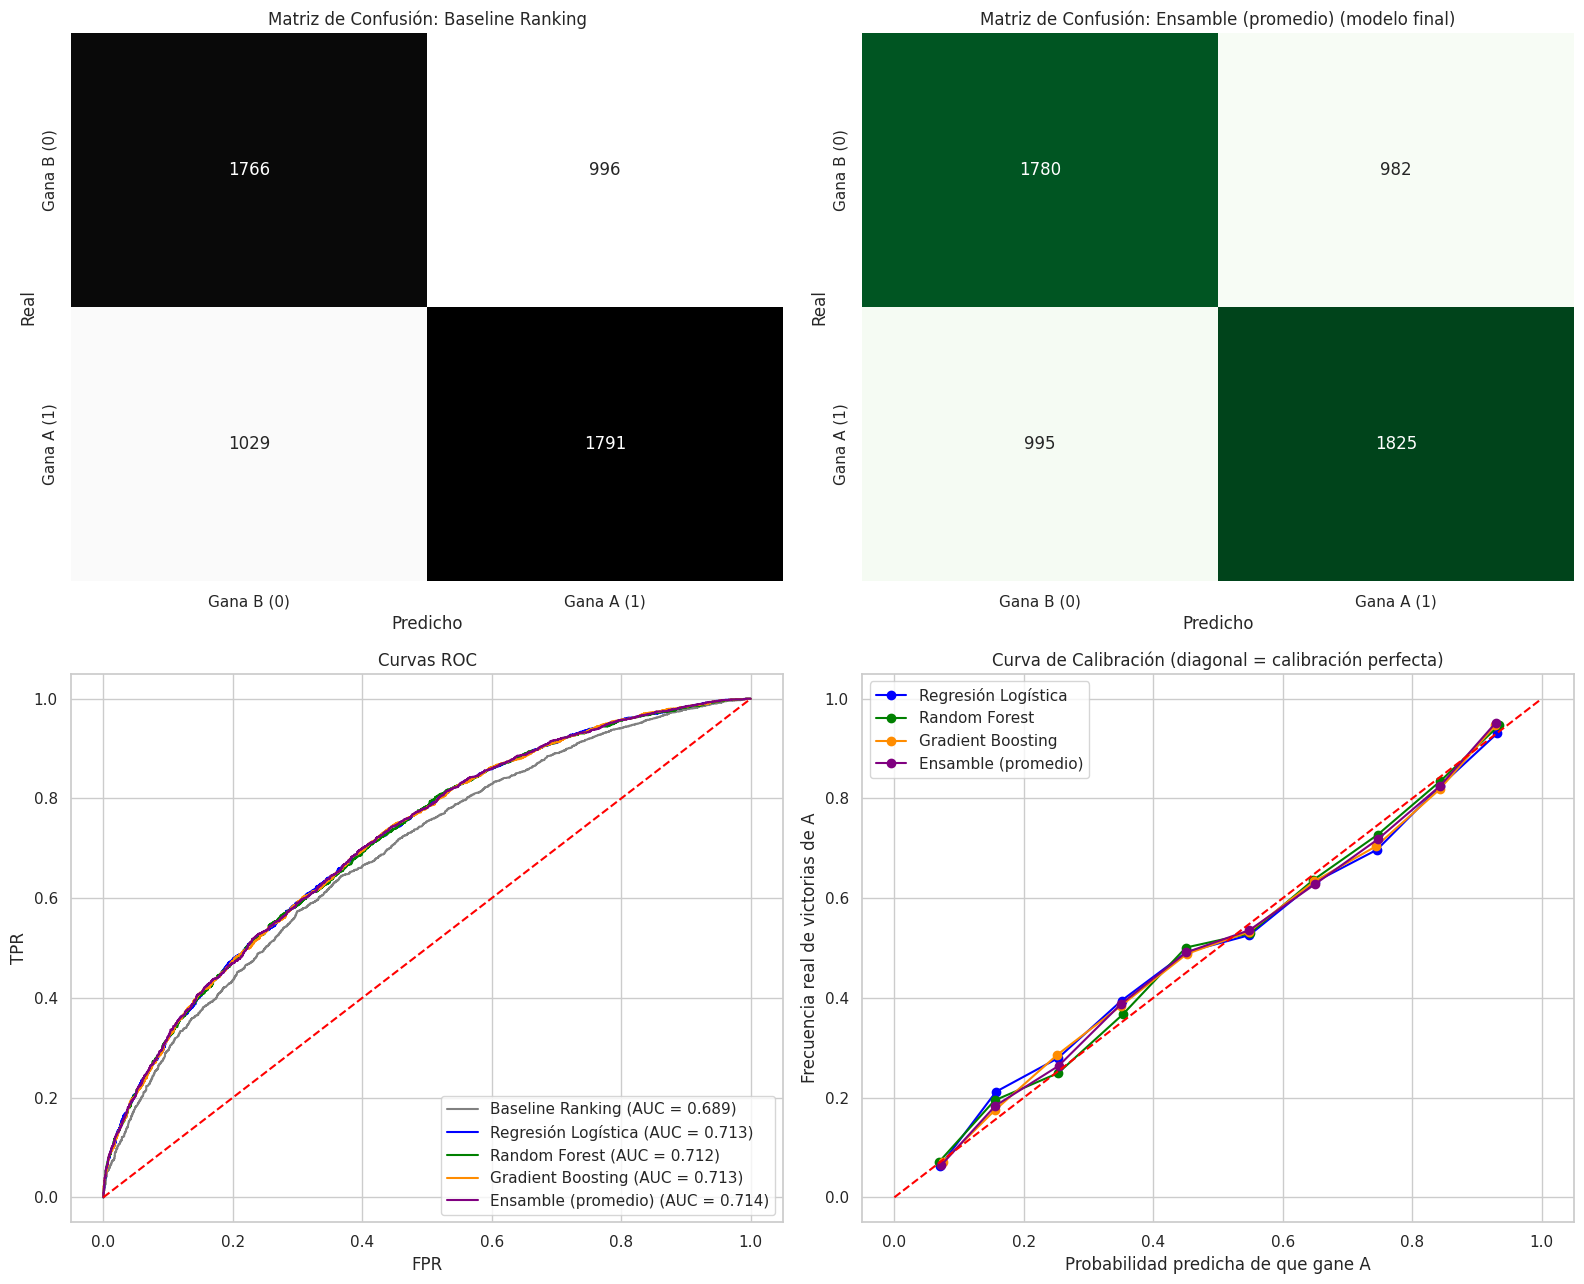

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             log_loss, brier_score_loss, confusion_matrix, roc_curve)
from sklearn.calibration import calibration_curve

def espejar(X):
    """Intercambia los roles de A y B (y cambia el signo de las diferencias)."""
    Xm = X.copy()
    for attr in ATRIBUTOS:
        Xm[f'{attr}_A'], Xm[f'{attr}_B'] = X[f'{attr}_B'].values, X[f'{attr}_A'].values
    Xm[COLUMNAS_DIFF] = -X[COLUMNAS_DIFF]
    return Xm

def proba_simetrica(modelo, X):
    """Probabilidad de que gane A, promediando A vs B y B vs A."""
    return (modelo.predict_proba(X)[:, 1] + 1 - modelo.predict_proba(espejar(X))[:, 1]) / 2

# Baseline: gana el mejor rankeado (empate -> más puntos)
a_mejor_rankeado = ((X_test['rank_A'] < X_test['rank_B']) |
                    ((X_test['rank_A'] == X_test['rank_B']) & (X_test['rank_points_A'] >= X_test['rank_points_B'])))
y_pred_rank = a_mejor_rankeado.astype(int).values
score_rank = X_test['diff_log_rank'].values

probas = {n: proba_simetrica(m, X_test) for n, m in modelos.items()}
predicciones = {n: (p >= 0.5).astype(int) for n, p in probas.items()}

def calcular_metricas(y_true, y_pred, y_score, es_probabilidad=True):
    return [accuracy_score(y_true, y_pred), precision_score(y_true, y_pred), recall_score(y_true, y_pred),
            f1_score(y_true, y_pred), roc_auc_score(y_true, y_score),
            log_loss(y_true, y_score) if es_probabilidad else np.nan,
            brier_score_loss(y_true, y_score) if es_probabilidad else np.nan]

df_comparativa = pd.DataFrame(
    {'Baseline (Ranking)': calcular_metricas(y_test, y_pred_rank, score_rank, es_probabilidad=False),
     **{n: calcular_metricas(y_test, predicciones[n], probas[n]) for n in modelos}},
    index=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Log-Loss', 'Brier Score'])
print("=== Tabla Comparativa de Desempeño en Test ===")
display(df_comparativa.round(4))

y_prob_final, y_pred_final = probas[nombre_final], predicciones[nombre_final]

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
etiquetas = ['Gana B (0)', 'Gana A (1)']
sns.heatmap(confusion_matrix(y_test, y_pred_rank), annot=True, fmt='d', cmap='Greys', ax=axes[0, 0], cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas)
axes[0, 0].set_title('Matriz de Confusión: Baseline Ranking')
sns.heatmap(confusion_matrix(y_test, y_pred_final), annot=True, fmt='d', cmap='Greens', ax=axes[0, 1], cbar=False,
            xticklabels=etiquetas, yticklabels=etiquetas)
axes[0, 1].set_title(f'Matriz de Confusión: {nombre_final} (modelo final)')
for ax in axes[0]:
    ax.set_xlabel('Predicho'); ax.set_ylabel('Real')

colores = {'Regresión Logística': 'blue', 'Random Forest': 'green', 'Gradient Boosting': 'darkorange', 'Ensamble (promedio)': 'purple'}
fpr, tpr, _ = roc_curve(y_test, score_rank)
axes[1, 0].plot(fpr, tpr, color='gray', label=f"Baseline Ranking (AUC = {roc_auc_score(y_test, score_rank):.3f})")
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1, 0].plot(fpr, tpr, color=colores[n], label=f"{n} (AUC = {roc_auc_score(y_test, p):.3f})")
    frac, media = calibration_curve(y_test, p, n_bins=10)
    axes[1, 1].plot(media, frac, marker='o', color=colores[n], label=n)
for ax in axes[1]:
    ax.plot([0, 1], [0, 1], color='red', linestyle='--')
axes[1, 0].set_title('Curvas ROC'); axes[1, 0].set_xlabel('FPR'); axes[1, 0].set_ylabel('TPR')
axes[1, 0].legend(loc='lower right')
axes[1, 1].set_title('Curva de Calibración (diagonal = calibración perfecta)')
axes[1, 1].set_xlabel('Probabilidad predicha de que gane A'); axes[1, 1].set_ylabel('Frecuencia real de victorias de A')
axes[1, 1].legend(loc='upper left')
plt.tight_layout()
plt.show()

### **¿Las probabilidades altas son exageradas?**
No, y lo podmos refutar ya que agrupamos lo partidos de test según la confianza del modelo final en el favorito y comparamos la probabilidad promedio predicha con el porcentaje real de victorias. También analizamos aparte los partidos **entre dos jugadores del top 10**, porque es el caso que genera dudas

In [17]:
df_conf = pd.DataFrame({'prob_favorito': np.maximum(y_prob_final, 1 - y_prob_final),
                        'gano_favorito': (y_pred_final == y_test.values),
                        'top10_vs_top10': ((X_test['rank_A'] <= 10) & (X_test['rank_B'] <= 10)).values})
df_conf['confianza'] = pd.cut(df_conf['prob_favorito'], [0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
                              labels=['50-60%', '60-70%', '70-80%', '80-90%', '90-100%'], include_lowest=True)

tabla_confianza = (df_conf.groupby('confianza', observed=True)
                   .agg(partidos=('gano_favorito', 'size'),
                        prob_predicha_media=('prob_favorito', 'mean'),
                        victorias_reales_favorito=('gano_favorito', 'mean')))
print("Confianza del modelo vs realidad (todos los partidos de test):")
display(tabla_confianza.round(3))

top = df_conf[df_conf['top10_vs_top10']]
print(f"\nPartidos top 10 vs top 10 en test: {len(top)}")
print(f"  Probabilidad media que el modelo le dio al favorito: {top['prob_favorito'].mean():.1%}")
print(f"  Porcentaje real de victorias del favorito:           {top['gano_favorito'].mean():.1%}")
print(f"  Partidos en los que el modelo dio más de 70%:        {(top['prob_favorito'] > 0.7).mean():.1%}")

Confianza del modelo vs realidad (todos los partidos de test):


,partidos,prob_predicha_media,victorias_reales_favorito
confianza,,,
50-60%,1888,0.549,0.523
60-70%,1631,0.650,0.620
70-80%,1180,0.747,0.727
80-90%,685,0.843,0.820
90-100%,198,0.929,0.944



Partidos top 10 vs top 10 en test: 120
  Probabilidad media que el modelo le dio al favorito: 67.1%
  Porcentaje real de victorias del favorito:           70.8%
  Partidos en los que el modelo dio más de 70%:        40.8%


### ¿El modelo depende solo del ranking? - Análisis de ablación
**Análisis de ablación:** Es un método que consiste en la **eliminación de un componente** de un sistema de IA para evaluar su importancia, tiene como propósito determinar la **contribución específica**de un componente al rendimiento global del sistema.
Para responder si nuestro modelo realmente utiliza el hitorial de los jugador o solo se apoya en la diferencia del ranking, lo entrenamos con tres conjuntos claves de variables:
1. **Solo raking:** Puesto y Puntos ATP.
2. **Solo historial (Sin ranking):** Elo, forma reciente, superficie, saque, devolución, H2H, físico y contexto --> No ve el ranking.
3. **Completo:** Utiliza todas las variables.
En caso de que el modelo que contempla `solo el historial` rinde casi igual que el `completo`, significa que el historial contiene la información relevante y que el `ranking` es un resumen del mismo historial.

In [18]:
from sklearn.base import clone

columnas_ranking = [c for c in features if c.startswith(('rank', 'diff_rank', 'diff_log_rank', 'diff_log_points'))]
conjuntos = {'Solo ranking': columnas_ranking + ['best_of'],
             'Solo historial (sin ranking)': [c for c in features if c not in columnas_ranking],
             'Completo': features}

filas_ablacion = []
for nombre, columnas in conjuntos.items():
    m = clone(modelo_final).fit(X_train[columnas], y_train)
    p = m.predict_proba(X_test[columnas])[:, 1]
    filas_ablacion.append({'Conjunto de variables': nombre, 'N° variables': len(columnas),
                           'Accuracy': accuracy_score(y_test, p >= 0.5), 'ROC-AUC': roc_auc_score(y_test, p),
                           'Log-Loss': log_loss(y_test, p)})
df_ablacion = pd.DataFrame(filas_ablacion).set_index('Conjunto de variables')
display(df_ablacion.round(4))

,N° variables,Accuracy,ROC-AUC,Log-Loss
Conjunto de variables,,,,
Solo ranking,9,0.6331,0.6902,0.6331
Solo historial (sin ranking),65,0.6456,0.7111,0.6187
Completo,73,0.6474,0.7132,0.6173


### **Importancia de Variables por Familia**

Medimos la importancia por **permutación agrupada**: desordenamos al mismo tiempo todas las variables de una familia (por ejemplo, las 6 columnas de Elo: A, B y diferencia, general y por superficie) y medimos cuánto cae el ROC-AUC en test. Agrupar evita un problema de la importancia variable por variable: cuando dos variables están correlacionadas (como `elo` y `rank_points`), desordenar una sola casi no afecta, porque el modelo usa la otra, y ambas parecen poco importantes.

,Caída de ROC-AUC,Desvío
Elo (general y superficie),0.0662,0.0028
Ranking ATP,0.0180,0.0027
Saque (forma reciente),0.0101,0.0022
"Edad, altura, experiencia, inactividad",0.0073,0.0015
Devolución (forma reciente),0.0036,0.0010
Historial directo (H2H),0.0006,0.0001
"Contexto (superficie, nivel, sets)",0.0005,0.0001
% victorias en la superficie,0.0004,0.0002
Forma reciente (últimos 10),0.0001,0.0002


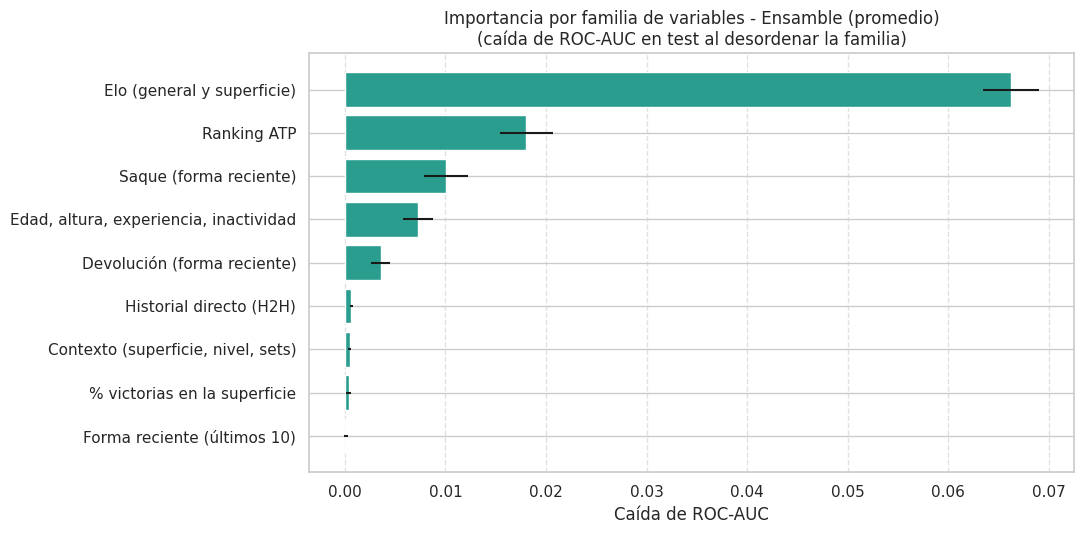

In [19]:
FAMILIAS = {
    'Ranking ATP': ['rank', 'rank_points'],
    'Elo (general y superficie)': ['elo', 'elo_sup'],
    'Forma reciente (últimos 10)': ['forma_10'],
    '% victorias en la superficie': ['win_pct_surface'],
    'Saque (forma reciente)': ['form_r_1stIn', 'form_r_1stWon', 'form_r_2ndWon', 'form_r_srv_won',
                               'form_r_ace', 'form_r_df', 'form_r_bpSaved'],
    'Devolución (forma reciente)': ['form_r_ret_won', 'form_r_bp_conv'],
    'Historial directo (H2H)': ['h2h'],
    'Edad, altura, experiencia, inactividad': ['age', 'ht', 'experiencia', 'dias_inactivo'],
}

def columnas_de_familia(atributos):
    cols = [f'{a}_{s}' for a in atributos for s in ('A', 'B')] + [f'diff_{a}' for a in atributos]
    if 'rank' in atributos:
        cols += ['diff_log_rank', 'diff_log_points']
    return cols

columnas_familia = {f: columnas_de_familia(a) for f, a in FAMILIAS.items()}
columnas_familia['Contexto (superficie, nivel, sets)'] = [c for c in features if c.startswith(('surface_', 'level_'))] + ['best_of']

rng = np.random.default_rng(SEMILLA)
muestra = X_test.sample(n=min(4000, len(X_test)), random_state=SEMILLA)
y_muestra = y_test.loc[muestra.index]
auc_base = roc_auc_score(y_muestra, modelo_final.predict_proba(muestra)[:, 1])

importancias = {}
for familia, cols in columnas_familia.items():
    caidas = []
    for _ in range(5):
        X_perm = muestra.copy()
        X_perm[cols] = muestra[cols].values[rng.permutation(len(muestra))]
        caidas.append(auc_base - roc_auc_score(y_muestra, modelo_final.predict_proba(X_perm)[:, 1]))
    importancias[familia] = (np.mean(caidas), np.std(caidas))

df_imp = (pd.DataFrame(importancias, index=['Caída de ROC-AUC', 'Desvío']).T
          .sort_values('Caída de ROC-AUC', ascending=False))
display(df_imp.round(4))

plt.figure(figsize=(11, 5.5))
plt.barh(df_imp.index[::-1], df_imp['Caída de ROC-AUC'][::-1], xerr=df_imp['Desvío'][::-1], color='#2a9d8f')
plt.title(f'Importancia por familia de variables - {nombre_final}\n(caída de ROC-AUC en test al desordenar la familia)')
plt.xlabel('Caída de ROC-AUC')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### **Identificación de patrones y tendencias**
Analizamos en dónde acierta y dónde falla el modelo final dentro de nuestro periodo de test, comparándolo con la linea base establecidad por el ranking:
* Por superficic.
* Por nivel de torneo.
* Por diferencia de ranking.

También medimos la proporción de **resultados inesperados** (Partidos que ganó el peor rankeado).

Proporción de sorpresas en test (gana el peor rankeado): 36.3%

Accuracy por superficie:


,partidos,accuracy_modelo,accuracy_ranking,mejora
superficie,,,,
Clay,1598,0.640,0.636,0.003
Grass,621,0.665,0.631,0.034
Hard,3363,0.645,0.639,0.007


Accuracy por nivel de torneo:


,partidos,accuracy_modelo,accuracy_ranking,mejora
nivel,,,,
250,1941,0.606,0.589,0.017
500,948,0.656,0.657,-0.001
A,177,0.610,0.576,0.034
F,30,0.733,0.733,0.000
G,1016,0.727,0.702,0.026
M,1470,0.638,0.649,-0.011


Accuracy por diferencia de ranking:


,partidos,accuracy_modelo,accuracy_ranking,mejora
dif_ranking,,,,
0-10,809,0.596,0.583,0.012
11-25,1071,0.599,0.586,0.013
26-50,1425,0.632,0.626,0.006
51-100,1313,0.692,0.686,0.005
101-250,713,0.710,0.693,0.017
>250,251,0.661,0.677,-0.016


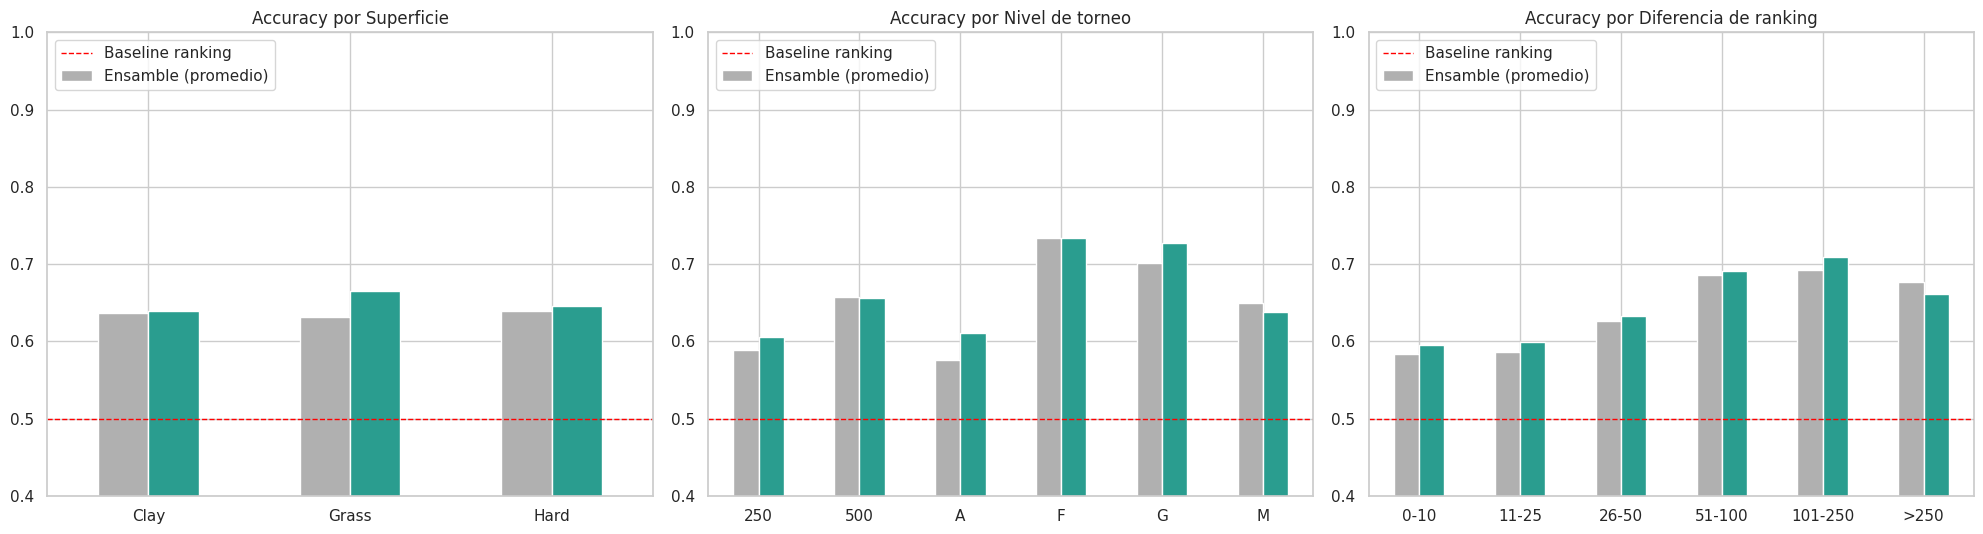

In [20]:
df_eval = df_model.loc[test_mask, ['superficie', 'nivel', 'diff_rank', 'target']].copy()
df_eval['acierto_modelo'] = (y_pred_final == y_test.values)
df_eval['acierto_ranking'] = (y_pred_rank == y_test.values)
df_eval['sorpresa'] = ~df_eval['acierto_ranking']
df_eval['dif_ranking'] = pd.cut(df_eval['diff_rank'].abs(), bins=[0, 10, 25, 50, 100, 250, np.inf],
                                labels=['0-10', '11-25', '26-50', '51-100', '101-250', '>250'], include_lowest=True)

def tabla_aciertos(columna):
    return (df_eval.groupby(columna, observed=True)
            .agg(partidos=('target', 'size'), accuracy_modelo=('acierto_modelo', 'mean'),
                 accuracy_ranking=('acierto_ranking', 'mean'))
            .assign(mejora=lambda t: t['accuracy_modelo'] - t['accuracy_ranking']))

tabla_superficie, tabla_nivel, tabla_dif_rank = (tabla_aciertos('superficie'), tabla_aciertos('nivel'),
                                                 tabla_aciertos('dif_ranking'))
print(f"Proporción de sorpresas en test (gana el peor rankeado): {df_eval['sorpresa'].mean():.1%}\n")
print("Accuracy por superficie:");            display(tabla_superficie.round(3))
print("Accuracy por nivel de torneo:");       display(tabla_nivel.round(3))
print("Accuracy por diferencia de ranking:"); display(tabla_dif_rank.round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
for ax, tabla, titulo in [(axes[0], tabla_superficie, 'Superficie'), (axes[1], tabla_nivel, 'Nivel de torneo'),
                          (axes[2], tabla_dif_rank, 'Diferencia de ranking')]:
    tabla[['accuracy_ranking', 'accuracy_modelo']].plot(kind='bar', ax=ax, color=['#b0b0b0', '#2a9d8f'], rot=0)
    ax.set_title(f'Accuracy por {titulo}'); ax.set_ylim(0.4, 1.0); ax.set_xlabel('')
    ax.axhline(0.5, color='red', linestyle='--', lw=1)
    ax.legend(['Baseline ranking', f'{nombre_final}'], loc='upper left')
plt.tight_layout()
plt.show()

### Resumen númerico de conclusiones

In [21]:
acc, auc, ll = df_comparativa.loc['Accuracy'], df_comparativa.loc['ROC-AUC'], df_comparativa.loc['Log-Loss']
print(f"Partidos de entrenamiento: {len(X_train)} | Partidos de test: {len(X_test)} | Variables: {len(features)}")
for n in df_comparativa.columns:
    print(f"{n:<22} -> Accuracy {acc[n]:.1%} | ROC-AUC {auc[n]:.3f} | Log-Loss {ll[n]:.4f}")
print(f"Modelo final: {nombre_final} | {resumen_cv.loc[nombre_final, 'Mejores parámetros']}")
print(f"Mejora del modelo final sobre el baseline: {acc[nombre_final] - acc['Baseline (Ranking)']:+.1%} de accuracy, "
      f"{auc[nombre_final] - auc['Baseline (Ranking)']:+.3f} de ROC-AUC")
print(f"Sorpresas en test (gana el peor rankeado): {df_eval['sorpresa'].mean():.1%}")
print(f"Familias más importantes: {df_imp.index[:3].tolist()}")

Partidos de entrenamiento: 64729 | Partidos de test: 5582 | Variables: 73
Baseline (Ranking)     -> Accuracy 63.7% | ROC-AUC 0.689 | Log-Loss nan
Regresión Logística    -> Accuracy 64.6% | ROC-AUC 0.713 | Log-Loss 0.6184
Random Forest          -> Accuracy 64.3% | ROC-AUC 0.712 | Log-Loss 0.6178
Gradient Boosting      -> Accuracy 64.5% | ROC-AUC 0.713 | Log-Loss 0.6177
Ensamble (promedio)    -> Accuracy 64.6% | ROC-AUC 0.714 | Log-Loss 0.6166
Modelo final: Ensamble (promedio) | promedio de los 3 modelos optimizados
Mejora del modelo final sobre el baseline: +0.9% de accuracy, +0.025 de ROC-AUC
Sorpresas en test (gana el peor rankeado): 36.3%
Familias más importantes: ['Elo (general y superficie)', 'Ranking ATP', 'Saque (forma reciente)']


## Implementación del simulador de partidos y torneos
El simulador usa el modelo final para predecir partidos y simular torneos completos. Además de la probabilidad, **se indica el por qué** avanza cada jugador.
### **Perfil actual de cada jugador**
Este se construye con las mismas variables que utiliza el modelo y además incluye todos los partidos jugados por el mismo hasta hoy:
* Ranking, puntos, edad y altura de su último partido registrado.
* Elo general y en la superficie del partido, actualizados después de su último partido.
* Forma reciente (últimos 10 partidos), estadísticas de saque y devolución (media móvil exponencial), % de victorias en la superficie, experencia y días sin competir.
* Historial directo contra el rival concreto.
### **¿Por qué gana?**
Acá realizamos un gráfico que indica el aporte de cada **familia de variables**, por cada partido calculamos cuánto aporta cada una de ellas a la probabilidad final.
**Códigos de nivel de torneo:**
* `G`: Grand Slam.
* `M`: Masters 1000.
* `500`: ATP Torneos 500 puntos.
* `250`: ATP Torneos 250 puntos.
* `A`: Otros torneos ATP.
* `F`: ATP Finals.

In [22]:
import difflib

FECHA_REFERENCIA = hist['tourney_date'].max()     # "hoy" para el simulador: último dato disponible
hist['player_name_lower'] = hist['player_name'].str.strip().str.lower()
NOMBRES_DISPONIBLES = hist['player_name'].unique()
SUPERFICIES_VALIDAS = sorted(c.replace('surface_', '') for c in features if c.startswith('surface_'))
NIVELES_VALIDOS = sorted(c.replace('level_', '') for c in features if c.startswith('level_'))
_cache_perfiles = {}

def obtener_perfil_jugador(nombre, surface):
    """Perfil actual del jugador (incluye todos sus partidos)."""
    clave = (nombre.strip().lower(), surface)
    if clave in _cache_perfiles:
        return dict(_cache_perfiles[clave])
    h = hist[hist['player_name_lower'] == clave[0]]
    if h.empty:
        sugerencias = difflib.get_close_matches(nombre, NOMBRES_DISPONIBLES, n=3)
        raise ValueError(f"No se encontró al jugador '{nombre}'. ¿Quisiste decir alguno de estos? {sugerencias}")
    h = h[h['player_id'] == h.loc[h['match_id'].idxmax(), 'player_id']].sort_values('match_id')
    ultimo = h.iloc[-1]
    pid = ultimo['player_id']
    perfil = {'nombre': ultimo['player_name'], 'player_id': pid,
              'rank': int(ultimo['rank']), 'rank_points': int(ultimo['rank_points']),
              'age': int(ultimo['age']), 'ht': int(ultimo['ht']),
              'elo': elo_actual[pid], 'elo_sup': elo_sup_actual[(pid, surface)],
              'forma_10': h['won'].tail(10).mean(),
              'experiencia': np.log1p(len(h)),
              'dias_inactivo': min((FECHA_REFERENCIA - ultimo['tourney_date']).days, 365)}
    for c in RATIOS:                                   # forma reciente incluyendo el último partido
        valor = ultimo[f'form_{c}_post']
        perfil[f'form_{c}'] = valor if pd.notna(valor) else hist.loc[es_train_hist, c].mean()
    h_sup = h[h['surface'] == surface]
    perfil['win_pct_surface'] = h_sup['won'].mean() if len(h_sup) else 0.5
    perfil['partidos_superficie'] = len(h_sup)
    _cache_perfiles[clave] = perfil
    return dict(perfil)

def construir_fila(perf_A, perf_B, surface, tourney_level, best_of):
    """Vector de entrada con exactamente las columnas de X_train."""
    fila = dict.fromkeys(features, 0)
    fila['best_of'] = best_of
    for attr in ATRIBUTOS:
        fila[f'{attr}_A'], fila[f'{attr}_B'] = perf_A[attr], perf_B[attr]
        fila[f'diff_{attr}'] = perf_A[attr] - perf_B[attr]
    fila['diff_log_rank'] = np.log(perf_B['rank']) - np.log(perf_A['rank'])
    fila['diff_log_points'] = np.log1p(perf_A['rank_points']) - np.log1p(perf_B['rank_points'])
    fila[f'surface_{surface}'] = 1
    fila[f'level_{tourney_level}'] = 1
    assert set(fila) == set(features)
    return fila

def analizar_partido(jugador_A, jugador_B, surface, tourney_level, best_of, modelo=None):
    """Probabilidad simétrica + aporte de cada familia de variables (en puntos de probabilidad para A)."""
    modelo = modelo_final if modelo is None else modelo
    surface, tourney_level = surface.capitalize(), str(tourney_level).upper()
    if surface not in SUPERFICIES_VALIDAS:
        raise ValueError(f"Superficie '{surface}' inválida. Opciones: {SUPERFICIES_VALIDAS}")
    if tourney_level not in NIVELES_VALIDOS:
        raise ValueError(f"Nivel '{tourney_level}' inválido. Opciones: {NIVELES_VALIDOS}")

    pA, pB = obtener_perfil_jugador(jugador_A, surface), obtener_perfil_jugador(jugador_B, surface)
    pA['h2h'] = h2h_actual[(pA['player_id'], pB['player_id'])]
    pB['h2h'] = h2h_actual[(pB['player_id'], pA['player_id'])]

    # Escenario original + un escenario por familia con esa familia "igualada" entre los dos jugadores
    escenarios = [(pA, pB)]
    for atributos in FAMILIAS.values():
        qA, qB = dict(pA), dict(pB)
        for a in atributos:
            qA[a] = qB[a] = (pA[a] + pB[a]) / 2
        escenarios.append((qA, qB))
    filas = []
    for qA, qB in escenarios:
        filas += [construir_fila(qA, qB, surface, tourney_level, best_of),
                  construir_fila(qB, qA, surface, tourney_level, best_of)]
    p = modelo.predict_proba(pd.DataFrame(filas)[features])[:, 1]
    prob_A_escenarios = (p[0::2] + 1 - p[1::2]) / 2          # simetría: promedio A-B y B-A
    prob_A = prob_A_escenarios[0]
    aportes_A = pd.Series(prob_A - prob_A_escenarios[1:], index=list(FAMILIAS))
    ganador_es_A = prob_A >= 0.5
    return {'perfil_A': pA, 'perfil_B': pB, 'prob_A': prob_A, 'prob_B': 1 - prob_A,
            'ganador': pA['nombre'] if ganador_es_A else pB['nombre'],
            'perdedor': pB['nombre'] if ganador_es_A else pA['nombre'],
            'prob_ganador': max(prob_A, 1 - prob_A),
            'aportes_ganador': (aportes_A if ganador_es_A else -aportes_A).sort_values(ascending=False),
            'surface': surface, 'tourney_level': tourney_level, 'best_of': best_of}

def tabla_comparativa(res):
    """Tabla lado a lado con las estadísticas clave de los dos jugadores."""
    pA, pB, s = res['perfil_A'], res['perfil_B'], res['surface']
    filas = {
        'Ranking ATP (puesto / puntos)': (f"{pA['rank']} / {pA['rank_points']}", f"{pB['rank']} / {pB['rank_points']}"),
        'Elo general': (f"{pA['elo']:.0f}", f"{pB['elo']:.0f}"),
        f'Elo en {s}': (f"{pA['elo_sup']:.0f}", f"{pB['elo_sup']:.0f}"),
        'Forma: victorias en últimos 10': (f"{pA['forma_10']:.0%}", f"{pB['forma_10']:.0%}"),
        f'% victorias en {s} (partidos)': (f"{pA['win_pct_surface']:.0%} ({pA['partidos_superficie']})",
                                          f"{pB['win_pct_surface']:.0%} ({pB['partidos_superficie']})"),
        '% puntos ganados con el saque': (f"{pA['form_r_srv_won']:.1%}", f"{pB['form_r_srv_won']:.1%}"),
        '% puntos ganados al resto': (f"{pA['form_r_ret_won']:.1%}", f"{pB['form_r_ret_won']:.1%}"),
        '% break points salvados': (f"{pA['form_r_bpSaved']:.1%}", f"{pB['form_r_bpSaved']:.1%}"),
        'Aces por punto de saque': (f"{pA['form_r_ace']:.1%}", f"{pB['form_r_ace']:.1%}"),
        'Historial directo (victorias)': (pA['h2h'], pB['h2h']),
        'Edad / días sin competir': (f"{pA['age']} / {pA['dias_inactivo']}", f"{pB['age']} / {pB['dias_inactivo']}"),
        'PROBABILIDAD DE VICTORIA': (f"{res['prob_A']:.1%}", f"{res['prob_B']:.1%}"),
    }
    return pd.DataFrame(filas, index=[pA['nombre'], pB['nombre']]).T

def texto_factores(aportes, n=3, umbral=0.005):
    a_favor = [f"{k} (+{v*100:.1f})" for k, v in aportes.items() if v > umbral][:n]
    en_contra = [f"{k} ({v*100:.1f})" for k, v in aportes[::-1].items() if v < -umbral][:2]
    return ', '.join(a_favor) or '—', ', '.join(en_contra) or '—'

def predecir_enfrentamiento(jugador_A, jugador_B, surface='Hard', tourney_level='250', best_of=3,
                            modelo=None, silencioso=False, grafico=True):
    """Predice un partido, muestra la comparación de estadísticas y explica el resultado."""
    res = analizar_partido(jugador_A, jugador_B, surface, tourney_level, best_of, modelo)
    if not silencioso:
        print(f"\n{'=' * 80}\n PREDICCIÓN: {res['perfil_A']['nombre']} vs {res['perfil_B']['nombre']} | "
              f"{res['surface']} | Nivel {res['tourney_level']} | Al mejor de {best_of} sets\n{'=' * 80}")
        display(tabla_comparativa(res))
        print(f"🏆 GANADOR PREDICHO: {res['ganador']} ({res['prob_ganador']:.1%})")
        a_favor, en_contra = texto_factores(res['aportes_ganador'])
        print(f"   ✅ Factores a favor (puntos de probabilidad): {a_favor}")
        print(f"   ❌ Factores en contra: {en_contra}")
        if grafico:
            ap = res['aportes_ganador'].sort_values() * 100
            plt.figure(figsize=(9, 4))
            plt.barh(ap.index, ap.values, color=['#2a9d8f' if v > 0 else '#e76f51' for v in ap.values])
            plt.axvline(0, color='black', lw=0.8)
            plt.title(f"¿Por qué gana {res['ganador']}? Aporte de cada familia de variables")
            plt.xlabel('Puntos de probabilidad a favor (+) o en contra (−) del ganador')
            plt.tight_layout()
            plt.show()
    return res

NOMBRES_RONDAS = {64: 'Treintaidosavos de Final', 32: 'Dieciseisavos de Final', 16: 'Octavos de Final',
                  8: 'Cuartos de Final', 4: 'Semifinales', 2: 'Final'}

def simular_torneo(jugadores, surface='Hard', tourney_level='250', best_of=3, modelo=None, detalle=True):
    """Simula un cuadro de eliminación directa y muestra, ronda por ronda, por qué avanza cada jugador."""
    n = len(jugadores)
    if n < 2 or (n & (n - 1)) != 0:
        raise ValueError("La cantidad de jugadores debe ser una potencia de 2 (2, 4, 8, 16, 32...).")
    cuadro, ronda_actual, registro = [list(jugadores)], list(jugadores), []
    if detalle:
        print(f"{'*' * 80}\n🏁 SIMULACIÓN DE TORNEO | {surface} | Nivel {tourney_level} | Al mejor de {best_of} sets\n{'*' * 80}")
    while len(ronda_actual) > 1:
        nombre_ronda = NOMBRES_RONDAS.get(len(ronda_actual), f'Ronda de {len(ronda_actual)}')
        filas, siguiente = [], []
        for i in range(0, len(ronda_actual), 2):
            res = analizar_partido(ronda_actual[i], ronda_actual[i + 1], surface, tourney_level, best_of, modelo)
            siguiente.append(res['ganador'])
            g_, p_ = ((res['perfil_A'], res['perfil_B']) if res['ganador'] == res['perfil_A']['nombre']
                      else (res['perfil_B'], res['perfil_A']))
            a_favor, en_contra = texto_factores(res['aportes_ganador'])
            filas.append({'Ronda': nombre_ronda, 'Ganador': g_['nombre'], 'Perdedor': p_['nombre'],
                          'Prob.': f"{res['prob_ganador']:.1%}",
                          'Rank (G-P)': f"{g_['rank']} - {p_['rank']}",
                          'Elo sup. (G-P)': f"{g_['elo_sup']:.0f} - {p_['elo_sup']:.0f}",
                          'Forma 10 (G-P)': f"{g_['forma_10']:.0%} - {p_['forma_10']:.0%}",
                          f'% vict. {surface} (G-P)': f"{g_['win_pct_surface']:.0%} - {p_['win_pct_surface']:.0%}",
                          '% pts saque (G-P)': f"{g_['form_r_srv_won']:.0%} - {p_['form_r_srv_won']:.0%}",
                          '% pts resto (G-P)': f"{g_['form_r_ret_won']:.0%} - {p_['form_r_ret_won']:.0%}",
                          'H2H (G-P)': f"{g_['h2h']} - {p_['h2h']}",
                          'Por qué avanza': a_favor, 'En contra': en_contra})
        registro += filas
        if detalle:
            print(f"\n🏆 {nombre_ronda.upper()}")
            display(pd.DataFrame(filas).drop(columns='Ronda'))
        cuadro.append(siguiente)
        ronda_actual = siguiente
    if detalle:
        print(f"\n{'=' * 80}\n🏆 CAMPEÓN: {ronda_actual[0].upper()}\n{'=' * 80}")
    return cuadro, pd.DataFrame(registro)

def graficar_cuadro(cuadro, titulo):
    nombres = ['1ra ronda', 'Octavos', 'Cuartos', 'Semifinal', 'Final', 'Campeón'][-len(cuadro):]
    alto = len(cuadro[0])
    plt.figure(figsize=(24, max(6, alto * 0.45)))
    plt.title(titulo, fontsize=18, fontweight='bold', pad=20)
    for r, participantes in enumerate(cuadro):
        x, paso_y = r * 1.2, alto / len(participantes)
        for idx, jugador in enumerate(participantes):
            y = idx * paso_y + paso_y / 2
            es_campeon = r == len(cuadro) - 1
            plt.text(x, y, f" {jugador} ", fontsize=9, va='center', ha='left',
                     bbox=dict(facecolor='#DFFF4F' if es_campeon else 'white', edgecolor='black',
                               boxstyle='round,pad=0.3', lw=2 if es_campeon else 1))
            if not es_campeon:
                paso_sig = alto / (len(participantes) / 2)
                y_sig = (idx // 2) * paso_sig + paso_sig / 2
                plt.plot([x + 0.9, x + 1.05, x + 1.05], [y, y, y_sig], color='#5c5bdf', alpha=0.6, lw=1.5)
                plt.plot([x + 1.05, x + 1.2], [y_sig, y_sig], color='#5c5bdf', alpha=0.6, lw=1.5)
        plt.text(x, alto + 0.6, nombres[r], fontsize=12, fontweight='bold')
    plt.xlim(-0.2, len(cuadro) * 1.2)
    plt.ylim(0, alto + 1.2)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def simular_torneo_32(surface='Hard', tourney_level='500', best_of=3, semilla=SEMILLA,
                      meses_actividad=12, min_partidos=10, detalle=True):
    """Cuadro de 32 jugadores ACTIVOS elegidos al azar (con semilla): detalle por ronda + gráfico."""
    recientes = hist[hist['tourney_date'] >= FECHA_REFERENCIA - pd.DateOffset(months=meses_actividad)]
    conteo = recientes['player_name'].value_counts()
    pool = sorted(conteo[conteo >= min_partidos].index)
    jugadores = list(np.random.default_rng(semilla).choice(pool, 32, replace=False))
    cuadro, registro = simular_torneo(jugadores, surface, tourney_level, best_of, detalle=detalle)
    graficar_cuadro(cuadro, f"Cuadro simulado (32 jugadores activos) | {surface} | Nivel {tourney_level} | semilla={semilla}")
    return cuadro, registro

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 250)
print(f"Simulador listo. Modelo: {nombre_final}. Fecha de referencia: {FECHA_REFERENCIA:%Y-%m-%d}")
print(f"Superficies válidas: {SUPERFICIES_VALIDAS} | Niveles válidos: {NIVELES_VALIDOS}")

Simulador listo. Modelo: Ensamble (promedio). Fecha de referencia: 2026-01-17
Superficies válidas: ['Carpet', 'Clay', 'Grass', 'Hard'] | Niveles válidos: ['250', '500', 'A', 'F', 'G', 'M']


### **Simulación 1 - Predicción de enfrentamientos individuales**
Realizamos la predicción entre dos jugadores, indicando el el porcentaje de victoria que tendra un jugador por sobre otro basado en el modelo.


 PREDICCIÓN: Francisco Cerundolo vs Mohammed Abdulla | Grass | Nivel M | Al mejor de 5 sets


,Francisco Cerundolo,Mohammed Abdulla
Ranking ATP (puesto / puntos),20 / 2035,1349 / 2
Elo general,1850,1469
Elo en Grass,1491,1500
Forma: victorias en últimos 10,40%,0%
% victorias en Grass (partidos),41% (17),50% (0)
% puntos ganados con el saque,59.6%,49.0%
% puntos ganados al resto,38.8%,26.7%
% break points salvados,61.4%,20.0%
Aces por punto de saque,4.9%,0.0%
Historial directo (victorias),0,0


🏆 GANADOR PREDICHO: Francisco Cerundolo (88.2%)
   ✅ Factores a favor (puntos de probabilidad): Ranking ATP (+20.5), Edad, altura, experiencia, inactividad (+4.4), Saque (forma reciente) (+3.3)
   ❌ Factores en contra: —


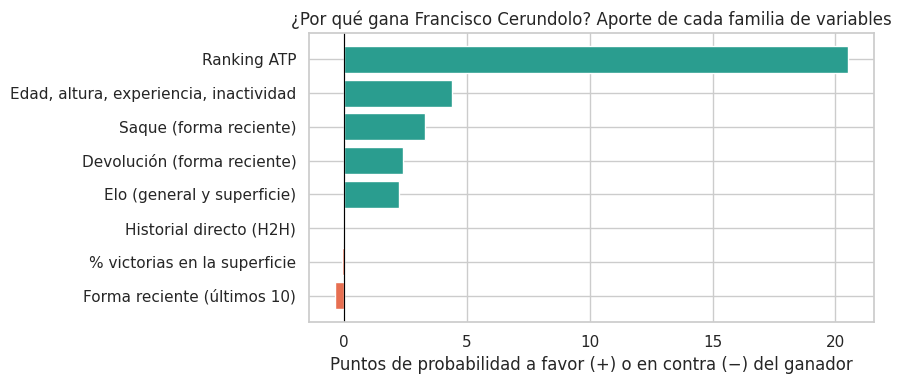

In [23]:
_ = predecir_enfrentamiento('Francisco Cerundolo', 'Mohammed Abdulla', surface='Grass', tourney_level='M', best_of=5)

### **Simulación 2 - Predicción de Octavos**
Realizamos la predicción de un cuadro de 8 jugadores de un circuito Reciente (Grand Slam sobre Arcilla).
Donde también mostramos la visualización de los avances dentro del cuadro mediante un gráfico.

In [24]:
cuadro_estrellas = ['Carlos Alcaraz', 'Jannik Sinner', 'Novak Djokovic', 'Daniil Medvedev',
                    'Alexander Zverev', 'Andrey Rublev', 'Stefanos Tsitsipas', 'Casper Ruud']
cuadro_8, detalle_8 = simular_torneo(cuadro_estrellas, surface='Clay', tourney_level='G', best_of=5)

********************************************************************************
🏁 SIMULACIÓN DE TORNEO | Clay | Nivel G | Al mejor de 5 sets
********************************************************************************

🏆 CUARTOS DE FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Carlos Alcaraz,Jannik Sinner,55.8%,1 - 2,2246 - 2109,80% - 100%,84% - 71%,69% - 74%,41% - 42%,10 - 6,"Elo (general y superficie) (+6.5), Ranking ATP (+1.6), Historial directo (H2H) (+1.5)","Saque (forma reciente) (-2.9), Devolución (forma reciente) (-1.2)"
1,Novak Djokovic,Daniil Medvedev,68.0%,5 - 13,2112 - 1894,80% - 80%,80% - 56%,71% - 67%,38% - 42%,9 - 5,"Elo (general y superficie) (+16.3), Ranking ATP (+5.3), Saque (forma reciente) (+4.9)","Edad, altura, experiencia, inactividad (-5.0), Devolución (forma reciente) (-3.2)"
2,Alexander Zverev,Andrey Rublev,69.6%,3 - 16,2018 - 1854,50% - 40%,73% - 66%,68% - 67%,35% - 36%,7 - 3,"Elo (general y superficie) (+12.2), Ranking ATP (+6.5), Historial directo (H2H) (+1.3)","Devolución (forma reciente) (-1.0), Forma reciente (últimos 10) (-0.5)"
3,Casper Ruud,Stefanos Tsitsipas,56.3%,13 - 33,1995 - 1987,60% - 50%,74% - 75%,69% - 66%,35% - 35%,3 - 2,"Ranking ATP (+3.0), Elo (general y superficie) (+1.8), Saque (forma reciente) (+1.5)","Edad, altura, experiencia, inactividad (-0.6)"



🏆 SEMIFINALES


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Carlos Alcaraz,Novak Djokovic,74.0%,1 - 5,2246 - 2112,80% - 80%,84% - 80%,69% - 71%,41% - 38%,4 - 4,"Elo (general y superficie) (+8.4), Ranking ATP (+6.3), Edad, altura, experiencia, inactividad (+4.4)",Saque (forma reciente) (-1.4)
1,Alexander Zverev,Casper Ruud,58.7%,3 - 13,2018 - 1995,50% - 60%,73% - 74%,68% - 69%,35% - 35%,4 - 2,"Ranking ATP (+5.6), Elo (general y superficie) (+3.9), Historial directo (H2H) (+0.7)",—



🏆 FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Carlos Alcaraz,Alexander Zverev,78.0%,1 - 3,2246 - 2018,80% - 50%,84% - 73%,69% - 68%,41% - 35%,6 - 6,"Elo (general y superficie) (+15.2), Ranking ATP (+5.2), Devolución (forma reciente) (+4.4)",—



🏆 CAMPEÓN: CARLOS ALCARAZ


### **Simulación 3 - Predicción de torneo de 32 Jugadores**
Esto se realiza eligiendo 32 jugadores al azar (con semilla fija), en donde obtenemos una simulación de un torneo.

********************************************************************************
🏁 SIMULACIÓN DE TORNEO | Clay | Nivel G | Al mejor de 3 sets
********************************************************************************

🏆 DIECISEISAVOS DE FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Andrey Rublev,Shintaro Mochizuki,82.4%,16 - 99,1854 - 1487,40% - 30%,66% - 0%,67% - 58%,36% - 36%,0 - 0,"Elo (general y superficie) (+18.7), Ranking ATP (+8.8), Saque (forma reciente) (+6.2)","Edad, altura, experiencia, inactividad (-0.7)"
1,Botic van de Zandschulp,Daniel Altmaier,54.9%,75 - 44,1672 - 1647,30% - 40%,49% - 42%,63% - 61%,35% - 30%,0 - 0,"Devolución (forma reciente) (+3.8), Elo (general y superficie) (+1.6), Saque (forma reciente) (+1.6)","Edad, altura, experiencia, inactividad (-1.5), Ranking ATP (-1.0)"
2,Yannick Hanfmann,Hamad Medjedovic,50.1%,117 - 96,1684 - 1593,60% - 30%,53% - 40%,68% - 65%,34% - 32%,0 - 1,"Elo (general y superficie) (+3.9), Saque (forma reciente) (+3.1), Devolución (forma reciente) (+2.4)","Edad, altura, experiencia, inactividad (-7.4), Forma reciente (últimos 10) (-1.4)"
3,Gabriel Diallo,Alexander Shevchenko,67.6%,41 - 104,1739 - 1670,40% - 60%,55% - 45%,68% - 60%,35% - 33%,0 - 0,"Saque (forma reciente) (+7.8), Ranking ATP (+4.2), Elo (general y superficie) (+4.0)",—
4,Tommy Paul,James Duckworth,85.5%,21 - 86,1926 - 1395,50% - 40%,53% - 25%,67% - 66%,38% - 32%,1 - 0,"Elo (general y superficie) (+20.2), Ranking ATP (+5.0), Devolución (forma reciente) (+2.2)",—
5,Casper Ruud,Marin Cilic,77.3%,13 - 70,1995 - 1784,60% - 40%,74% - 59%,69% - 66%,35% - 30%,4 - 0,"Elo (general y superficie) (+10.3), Ranking ATP (+6.6), Devolución (forma reciente) (+2.6)",Forma reciente (últimos 10) (-0.7)
6,Ben Shelton,Francisco Comesana,68.5%,8 - 66,1781 - 1683,40% - 40%,53% - 46%,67% - 65%,31% - 34%,1 - 0,"Ranking ATP (+8.0), Elo (general y superficie) (+7.7), Edad, altura, experiencia, inactividad (+2.8)",Devolución (forma reciente) (-1.6)
7,Karen Khachanov,Cameron Norrie,54.1%,17 - 28,1870 - 1858,30% - 60%,59% - 61%,67% - 69%,36% - 35%,5 - 3,"Ranking ATP (+2.1), Edad, altura, experiencia, inactividad (+1.2), Elo (general y superficie) (+1.1)",Saque (forma reciente) (-2.0)
8,Arthur Fils,Hugo Dellien,90.3%,21 - 121,1970 - 1526,50% - 20%,62% - 35%,65% - 57%,39% - 32%,0 - 0,"Elo (general y superficie) (+17.8), Ranking ATP (+7.1), Saque (forma reciente) (+4.3)",—
9,Flavio Cobolli,Jaime Faria,82.5%,22 - 117,1894 - 1425,40% - 30%,60% - 25%,65% - 61%,33% - 34%,0 - 0,"Elo (general y superficie) (+19.2), Ranking ATP (+6.7), Saque (forma reciente) (+2.2)",—



🏆 OCTAVOS DE FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Andrey Rublev,Botic van de Zandschulp,74.1%,16 - 75,1854 - 1672,40% - 30%,66% - 49%,67% - 63%,36% - 35%,2 - 1,"Elo (general y superficie) (+9.5), Ranking ATP (+5.6), Saque (forma reciente) (+3.9)",—
1,Gabriel Diallo,Yannick Hanfmann,62.1%,41 - 117,1739 - 1684,40% - 60%,55% - 53%,68% - 68%,35% - 34%,0 - 0,"Edad, altura, experiencia, inactividad (+5.3), Ranking ATP (+3.6), Elo (general y superficie) (+1.7)",—
2,Casper Ruud,Tommy Paul,53.7%,13 - 21,1995 - 1926,60% - 50%,74% - 53%,69% - 67%,35% - 38%,4 - 2,"Elo (general y superficie) (+3.4), Ranking ATP (+1.5), % victorias en la superficie (+0.9)",Devolución (forma reciente) (-3.1)
3,Karen Khachanov,Ben Shelton,50.5%,17 - 8,1870 - 1781,30% - 40%,59% - 53%,67% - 67%,36% - 31%,0 - 2,"Devolución (forma reciente) (+4.3), Elo (general y superficie) (+1.9), Saque (forma reciente) (+0.8)","Ranking ATP (-3.6), Edad, altura, experiencia, inactividad (-2.6)"
4,Arthur Fils,Flavio Cobolli,60.6%,21 - 22,1970 - 1894,50% - 40%,62% - 60%,65% - 65%,39% - 33%,2 - 0,"Elo (general y superficie) (+6.8), Devolución (forma reciente) (+4.0), Historial directo (H2H) (+1.1)","Edad, altura, experiencia, inactividad (-1.4), Saque (forma reciente) (-0.6)"
5,Ugo Humbert,Benjamin Bonzi,60.3%,36 - 53,1509 - 1577,70% - 50%,31% - 33%,69% - 65%,36% - 32%,0 - 2,"Saque (forma reciente) (+4.2), Edad, altura, experiencia, inactividad (+3.9), Devolución (forma reciente) (+3.2)","Forma reciente (últimos 10) (-1.0), Historial directo (H2H) (-0.7)"
6,Jesper de Jong,Alex Michelsen,53.8%,71 - 37,1763 - 1462,40% - 50%,55% - 31%,64% - 62%,33% - 37%,0 - 0,"Elo (general y superficie) (+10.2), Saque (forma reciente) (+2.9), Forma reciente (últimos 10) (+0.5)","Edad, altura, experiencia, inactividad (-5.3), Devolución (forma reciente) (-3.2)"
7,Alejandro Davidovich Fokina,Damir Dzumhur,71.1%,15 - 66,1769 - 1711,60% - 20%,54% - 46%,65% - 59%,35% - 36%,2 - 0,"Elo (general y superficie) (+6.9), Ranking ATP (+6.7), Saque (forma reciente) (+5.2)",Forma reciente (últimos 10) (-1.0)



🏆 CUARTOS DE FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Andrey Rublev,Gabriel Diallo,60.3%,16 - 41,1854 - 1739,40% - 40%,66% - 55%,67% - 68%,36% - 35%,0 - 0,"Elo (general y superficie) (+8.2), Ranking ATP (+3.8), Devolución (forma reciente) (+1.4)","Saque (forma reciente) (-1.4), Edad, altura, experiencia, inactividad (-1.0)"
1,Casper Ruud,Karen Khachanov,59.0%,13 - 17,1995 - 1870,60% - 30%,74% - 59%,69% - 67%,35% - 36%,2 - 1,"Elo (general y superficie) (+6.9), Saque (forma reciente) (+1.2), Ranking ATP (+1.0)","Devolución (forma reciente) (-1.0), Forma reciente (últimos 10) (-0.7)"
2,Arthur Fils,Ugo Humbert,69.7%,21 - 36,1970 - 1509,50% - 70%,62% - 31%,65% - 69%,39% - 36%,1 - 4,"Elo (general y superficie) (+18.4), Ranking ATP (+2.8), Devolución (forma reciente) (+2.0)","Saque (forma reciente) (-3.7), Historial directo (H2H) (-0.6)"
3,Alejandro Davidovich Fokina,Jesper de Jong,64.0%,15 - 71,1769 - 1763,60% - 40%,54% - 55%,65% - 64%,35% - 33%,0 - 1,"Ranking ATP (+7.8), Elo (general y superficie) (+4.2), Devolución (forma reciente) (+2.2)",Forma reciente (últimos 10) (-0.5)



🏆 SEMIFINALES


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Casper Ruud,Andrey Rublev,58.2%,13 - 16,1995 - 1854,60% - 40%,74% - 66%,69% - 67%,35% - 36%,3 - 5,"Elo (general y superficie) (+8.3), Saque (forma reciente) (+1.4), Ranking ATP (+1.0)","Devolución (forma reciente) (-1.4), Forma reciente (últimos 10) (-0.8)"
1,Arthur Fils,Alejandro Davidovich Fokina,62.7%,21 - 15,1970 - 1769,50% - 60%,62% - 54%,65% - 65%,39% - 35%,2 - 2,"Elo (general y superficie) (+9.0), Devolución (forma reciente) (+3.0)",Ranking ATP (-1.7)



🏆 FINAL


,Ganador,Perdedor,Prob.,Rank (G-P),Elo sup. (G-P),Forma 10 (G-P),% vict. Clay (G-P),% pts saque (G-P),% pts resto (G-P),H2H (G-P),Por qué avanza,En contra
0,Casper Ruud,Arthur Fils,51.3%,13 - 21,1995 - 1970,60% - 50%,74% - 62%,69% - 65%,35% - 39%,1 - 1,"Saque (forma reciente) (+4.8), Ranking ATP (+1.4)",Devolución (forma reciente) (-2.8)



🏆 CAMPEÓN: CASPER RUUD


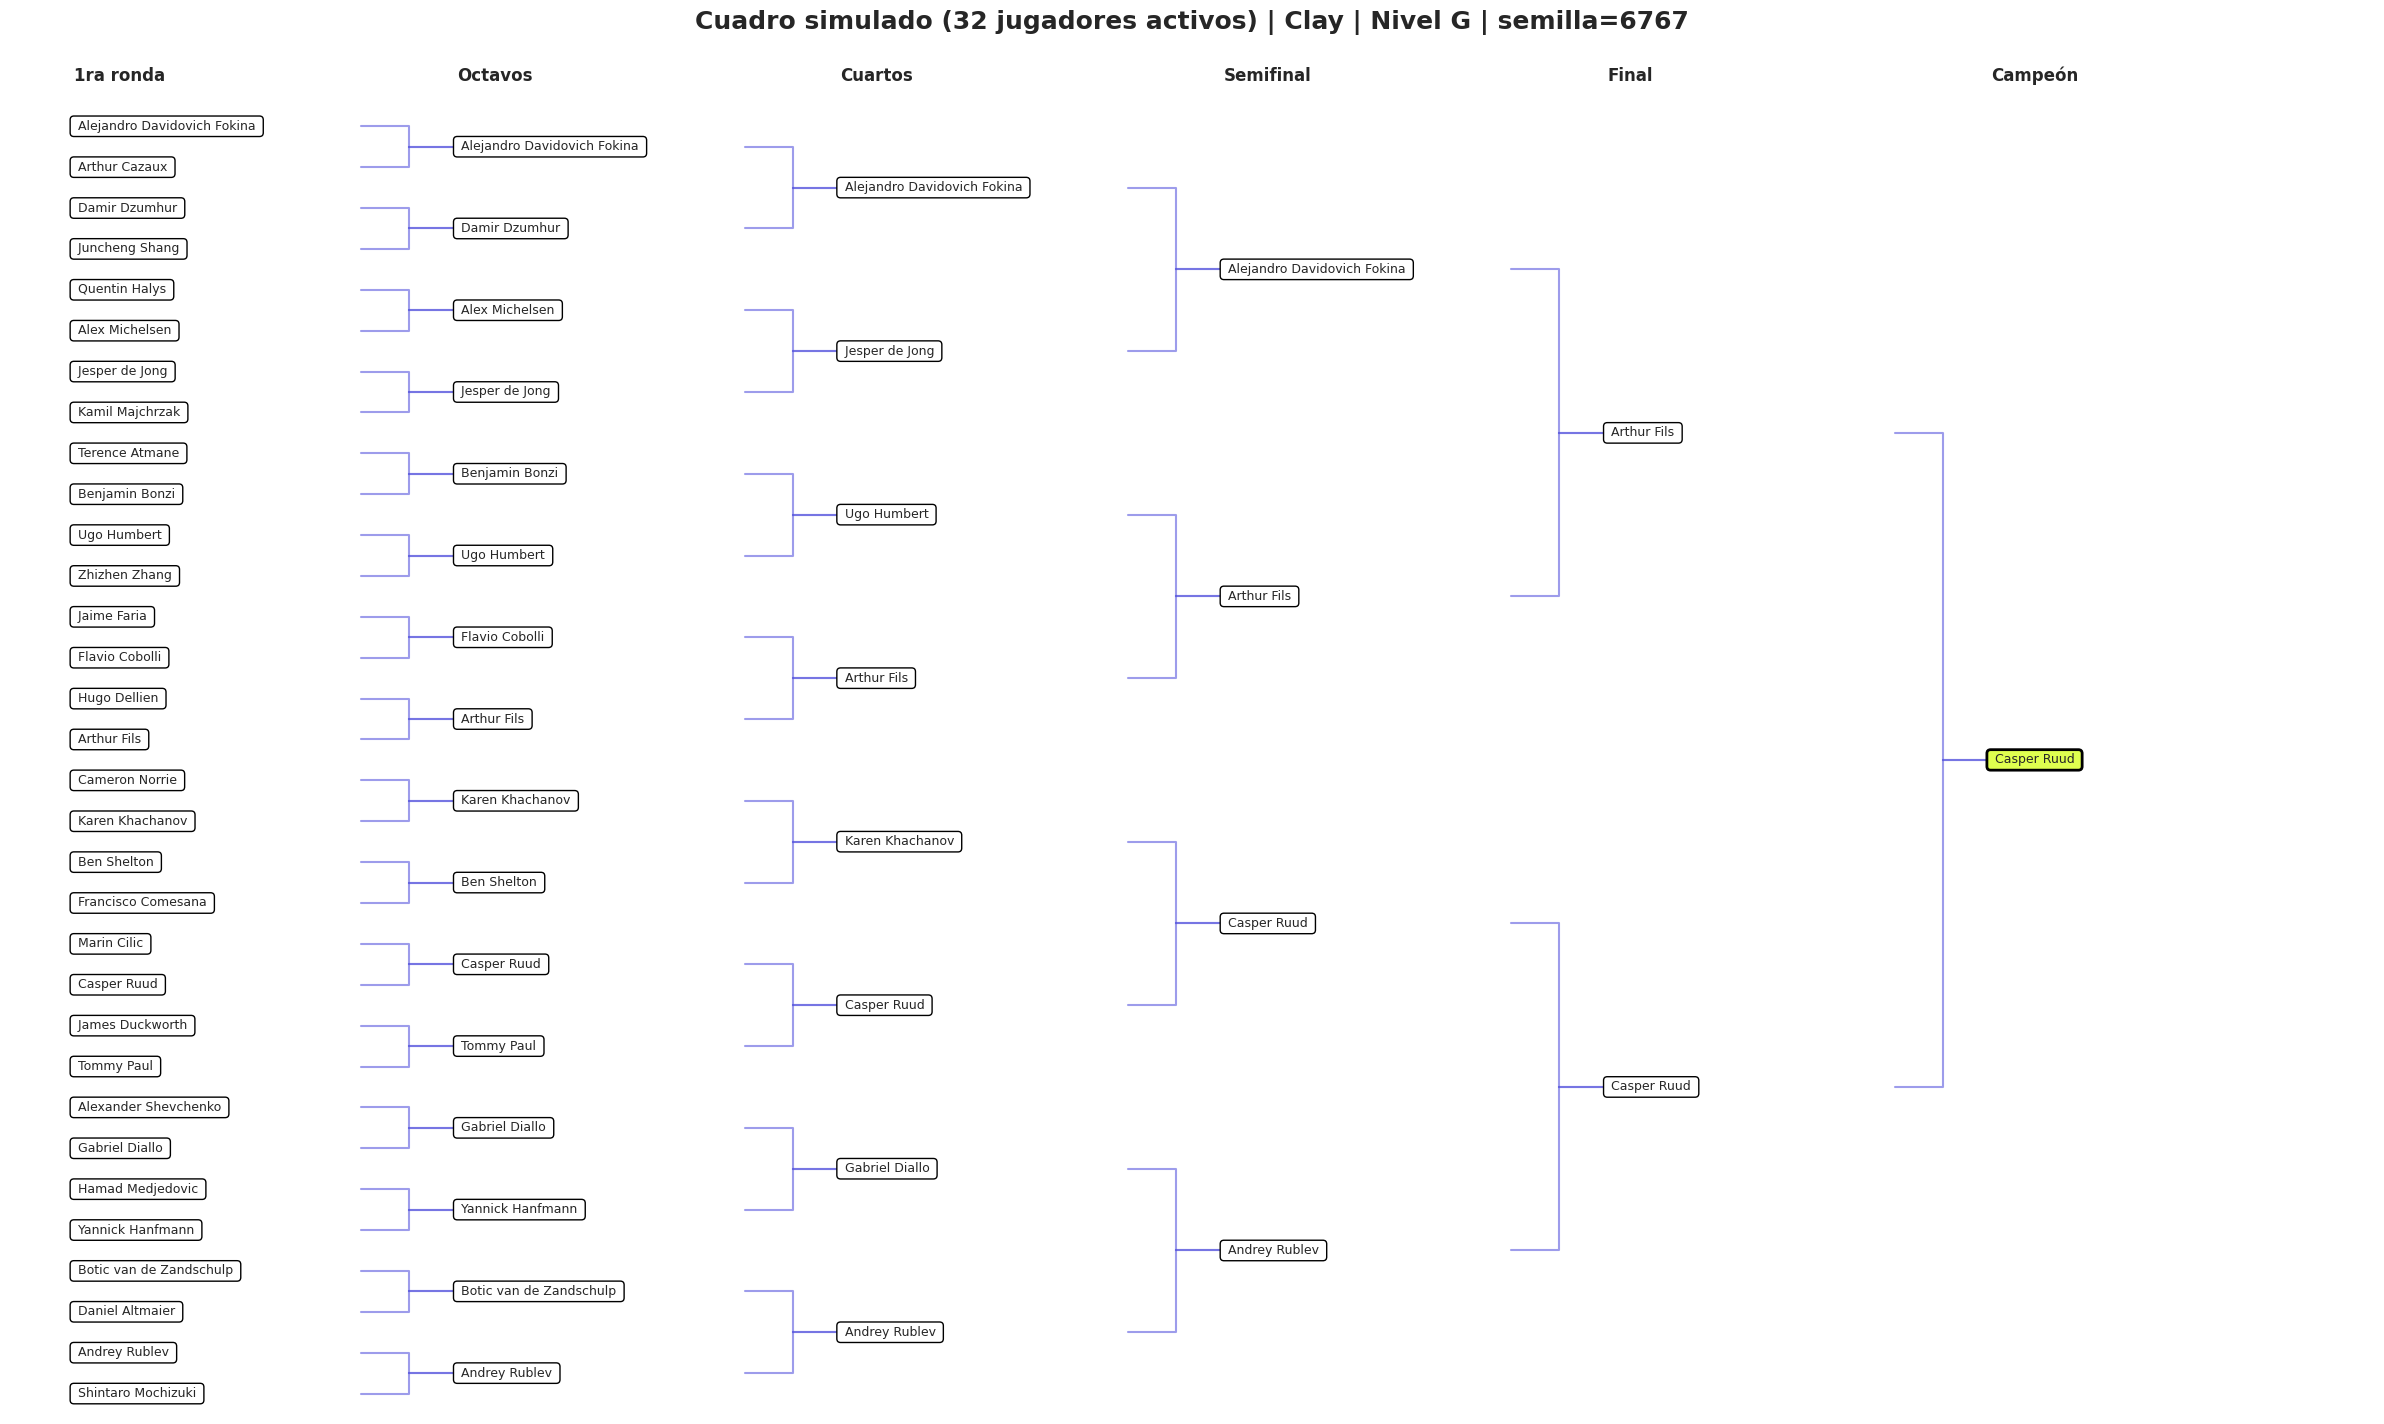

In [25]:
cuadro_32, detalle_32 = simular_torneo_32(surface='Clay', tourney_level='G', best_of=3, semilla=6767)

## **Conclusiones**

**1. Desempeño.** El modelo final (ensamble de Regresión Logística, Random Forest y Gradient Boosting) alcanzó en test (2024 en adelante) **≈64,6% de accuracy**, **ROC-AUC ≈0,714** y **Log-Loss ≈0,617**. Mejora al baseline "gana el mejor rankeado" (63,7%; ROC-AUC 0,689) y a cada modelo por separado. Como alrededor del **36% de los partidos los gana el peor rankeado**, existe un techo natural para cualquier predicción basada solo en información previa al partido.

**2. El modelo usa el historial completo, no solo el ranking.**
* En el análisis de ablación, el modelo **sin ninguna variable de ranking** (solo historial) obtuvo ≈64,6% de accuracy y ROC-AUC ≈0,711, prácticamente lo mismo que el modelo completo (≈64,7%; 0,713) y bastante más que el modelo que solo ve el ranking (≈63,3%; 0,690).
* La familia más importante es el **rating Elo** (caída de ROC-AUC ≈0,066 al desordenarla), casi cuatro veces más que el ranking ATP (≈0,018). Le siguen las estadísticas de saque y los factores físicos y de actividad.

**3. Las probabilidades altas están respaldadas por los datos.** En los partidos de test en los que el modelo le dio al favorito **más de 90%** (198 partidos), el favorito ganó el **≈94%** de las veces. En los partidos **top 10 vs top 10** (120 partidos), el modelo le asignó al favorito en promedio **≈67%**, y el favorito ganó el **≈70,8%**. El modelo no exagera; si acaso, es levemente conservador.

**4. Errores (falsos positivos y negativos).** Con el target simetrizado al azar, un falso positivo y un falso negativo son el mismo error: elegir al jugador que perdió. Por eso F1 ≈ Accuracy y mover el umbral no ayuda. La mejora frente al ranking vino de **agregar información** (Elo, forma reciente, porcentajes de saque y devolución, H2H), y la familia más influyente fue el Elo.

**5. Partición temporal.** Fijamos el corte en el 1 de enero de 2024 (92,1% train / 7,9% test). El test cubre las temporadas 2024 y 2025 completas, con todas las superficies y niveles de torneo, y el modelo se evalúa sobre partidos posteriores a todo su entrenamiento. Un reparto aleatorio habría permitido entrenar con partidos posteriores a los que se predicen, lo que daría una evaluación optimista. Frente al sobreajuste, controlamos la complejidad con la regularización de los hiperparámetros y con validación cruzada temporal (TimeSeriesSplit) dentro del período de entrenamiento.

## **Aspectos a mejorar**

Todavía no evaluamos alternativas de reentrenamiento, como ponderar los partidos recientes o limitar el histórico a partir de 2010, que podrían mejorar la estimación de la forma actual de los jugadores. Tampoco incorporamos cuotas de mercado, que resumen información pública previa al partido, ni datos de lesiones o cansancio, que hoy no están en la base. La evolución del rendimiento de cada jugador a lo largo de su carrera, planteada en la Entrega 1, queda como trabajo futuro.



 PREDICCIÓN: Holger Rune vs Valentin Vacherot | Clay | Nivel 250 | Al mejor de 3 sets


,Holger Rune,Valentin Vacherot
Ranking ATP (puesto / puntos),11 / 3090,32 / 1469
Elo general,1914,1898
Elo en Clay,1917,1448
Forma: victorias en últimos 10,70%,60%
% victorias en Clay (partidos),63% (89),14% (7)
% puntos ganados con el saque,66.1%,65.6%
% puntos ganados al resto,38.7%,33.1%
% break points salvados,58.7%,60.4%
Aces por punto de saque,9.3%,10.9%
Historial directo (victorias),0,1


🏆 GANADOR PREDICHO: Holger Rune (75.5%)
   ✅ Factores a favor (puntos de probabilidad): Elo (general y superficie) (+15.7), Devolución (forma reciente) (+3.0), Ranking ATP (+2.9)
   ❌ Factores en contra: —


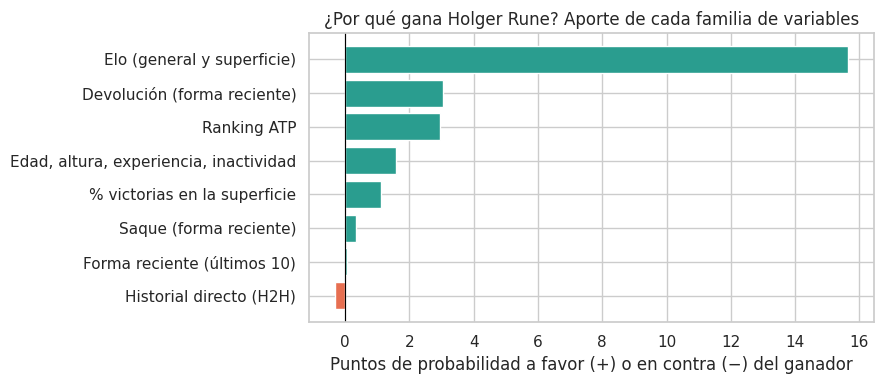

In [26]:
t = predecir_enfrentamiento('Holger Rune', 'Valentin Vacherot', surface='Clay', tourney_level='250', best_of=3)

# Análisis Predictivo del Circuito Asociación Tenis Profesional (ATP)
### Mirar el ranking es fácil. Entender el partido, no tanto.

**Trabajo Práctico Integrador – Entrega 4 (Presentación final)**
Cátedra de Ciencia de Datos · UTN FRC · Curso 5K2 · Grupo N° 4

Esta sección reúne la narrativa de la presentación final, siguiendo la consigna de la Entrega 4 y la estructura de *data storytelling* vista en la cátedra (título, contexto, evidencia, desenlace). Cada gráfico se genera con una celda de código al final de esta sección, a partir de las variables que produce el notebook.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

CARPETA_FIGURAS = 'figuras_storytelling'
os.makedirs(CARPETA_FIGURAS, exist_ok=True)

# Paleta: 2 colores principales + 1 neutro + 1 de resalte (criterio de diseño visto en la cátedra)
AZUL, VERDE, GRIS, NARANJA = '#0B6E99', '#2A9D8F', '#A0AAB4', '#E76F51'
plt.rcParams.update({'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 14, 'figure.dpi': 110})

NOMBRES_NIVEL = {'G': 'Grand Slam', 'M': 'Masters 1000', 'F': 'ATP Finals', 'A': 'Otros ATP',
                 '500': 'ATP 500', '250': 'ATP 250', 'D': 'Copa Davis', 'O': 'Juegos Olímpicos'}

def guardar_figura(fig, nombre):
    ruta = os.path.join(CARPETA_FIGURAS, nombre + '.png')
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print('Figura guardada en:', ruta)
    return ruta

## 1. Propuesta de valor: lo que obtienen con esta idea

Imaginen una herramienta que, antes de cada partido del circuito ATP, les dice quién tiene más chances de ganar y por qué. Eso es lo que proponemos. Nuestro modelo acierta el **64,6 %** de los partidos de 2024 a 2026, frente al **63,7 %** de la regla del ranking, y sus probabilidades son confiables: cuando asigna 90 %, el favorito gana cerca del 94 %.

Lo que se llevan con esta idea:

- Una predicción que supera al ranking, con la explicación de cada factor: Elo, forma reciente, saque, devolución.
- Probabilidades que se pueden usar: no solo el favorito, también cuánto confiar en él.
- Un simulador de torneos que muestra cómo avanza cada jugador, ronda por ronda.
- Un ciclo de datos completo y reproducible, documentado en un notebook y listo para crecer.

Somos honestos con los límites: el azar pone un techo y no recomendamos apostar con este modelo. Por eso proponemos tomar la idea como base de la próxima iteración.

## 2. Contexto: el problema y la pregunta

### 2.1 El problema

Un partido de tenis enfrenta a dos personas con historias, superficies y momentos de forma muy distintos. Anticipar al ganador interesa a periodistas y analistas, a los equipos técnicos que preparan un rival, y a cualquiera que quiera entender qué factores pesan de verdad. La pregunta central es:

> **¿Qué tan bien puede predecirse el ganador de un partido usando solo información disponible antes de que se juegue?**

### 2.2 Objetivo e hipótesis

El objetivo es construir un modelo de clasificación que estime la probabilidad de victoria de un jugador frente a otro, y un simulador de torneos que use esas probabilidades. Planteamos tres hipótesis:

- **H1.** El historial del jugador (Elo, forma, saque, devolución) contiene más información predictiva que el ranking ATP.
- **H2.** Las probabilidades del modelo están bien calibradas: cuando asigna 90 %, el resultado se acerca al 90 %.
- **H3.** El contexto (superficie y nivel del torneo) cambia cuánto puede predecirse un partido.

### 2.3 Actores, tiempo y lugar

- **Actores:** jugadores del circuito masculino profesional (ATP), sus equipos técnicos y el público que sigue el circuito.
- **Tiempo:** desde 2000 hasta comienzos de 2026. Entrenamos con los partidos anteriores al 1 de enero de 2024 y evaluamos con los posteriores. Así replicamos el uso real: predecir partidos futuros con datos del pasado.
- **Lugar:** torneos ATP de todo el mundo, en cuatro superficies: cemento (*hard*), arcilla (*clay*), césped (*grass*) y moqueta (*carpet*).

### 2.4 Fuente de datos

Usamos la base **TML-Database**, mantenida por Tennismylife a partir de un *scraping* de ATP Tour y de las bases abiertas de Jeff Sackmann. Cubre la era abierta completa y supera ampliamente el mínimo de 20.000 filas pedido en la Entrega 1: contiene **78.091 partidos** crudos con 50 columnas (atributos del torneo, del ganador, del perdedor, marcador y estadísticas de juego), y una tabla de jugadores con 7.643 registros. Para el análisis tomamos el período 2000–2026.

### 2.5 Dominio, columnas y unión de fuentes

El dominio es el tenis profesional masculino. Cada fila de la tabla de partidos es un encuentro, con torneo, superficie, ronda, ganador, perdedor, marcador y estadísticas de juego. Trabajamos con 50 columnas, que se agrupan así:

| Grupo de columnas | Ejemplos | Tipo de dato |
|---|---|---|
| Torneo | tourney_name, surface, tourney_level, tourney_date | Texto y fecha |
| Jugadores | winner_name, winner_rank, winner_age, winner_ht | Texto y numérico |
| Resultado | score, best_of, round, minutes | Texto y numérico |
| Estadísticas de juego | w_ace, w_df, w_svpt, l_bpFaced | Numérico (enteros) |

Unimos dos fuentes: la tabla de partidos y la tabla de jugadores, que aporta fecha de nacimiento, altura y mano hábil. La unión se hace por el identificador del jugador, así que la altura o la edad que falta en un partido se puede recuperar desde la tabla de jugadores.

**Glosario rápido.** *Ranking ATP*: posición oficial según los puntos de las últimas 52 semanas. *Elo*: rating que se actualiza con cada resultado, según quién gana y cuánto se esperaba ese resultado. *Superficie*: cemento, arcilla, césped o moqueta; cambia mucho el estilo de juego. *Break point*: oportunidad de quebrar el saque del rival.

**Hipótesis de trabajo.** H1: el historial del jugador aporta más que el ranking oficial. H2: las probabilidades del modelo están bien calibradas. H3: el contexto (superficie y nivel del torneo) cambia cuánto se puede predecir.

Figura guardada en: figuras_storytelling/fig01_partidos_por_anio.png


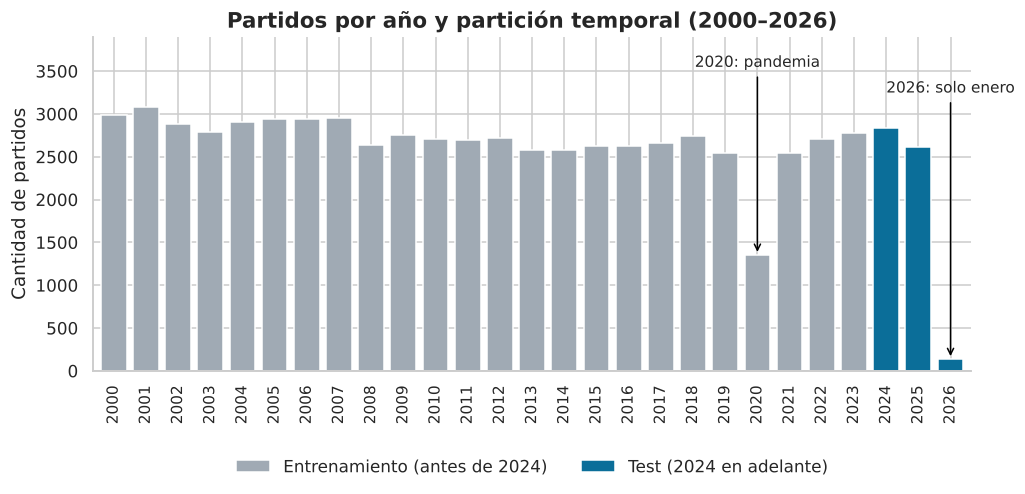

In [ ]:
anios = df_model['tourney_date'].dt.year
grupo = np.where(train_mask, 'Entrenamiento (antes de 2024)', 'Test (2024 en adelante)')
conteo = (pd.DataFrame({'anio': anios, 'grupo': grupo})
          .groupby(['anio', 'grupo']).size().unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(9.5, 4.8))
conteo.plot(kind='bar', stacked=True, ax=ax, color=[GRIS, AZUL], width=0.8)

pos_2020 = list(conteo.index).index(2020)
ax.annotate('2020: pandemia', xy=(pos_2020, conteo.loc[2020].sum()),
            xytext=(pos_2020, 3550), ha='center', fontsize=10,
            arrowprops=dict(arrowstyle='->', color='black'))
pos_2026 = len(conteo) - 1
ax.annotate('2026: solo enero', xy=(pos_2026, conteo.loc[2026].sum()),
            xytext=(pos_2026, 3250), ha='center', fontsize=10,
            arrowprops=dict(arrowstyle='->', color='black'))
ax.set_ylim(0, 3900)
ax.set_title('Partidos por año y partición temporal (2000–2026)')
ax.set_xlabel('')
ax.set_ylabel('Cantidad de partidos')
ax.set_xticklabels(conteo.index, rotation=90, fontsize=10)
ax.legend(title=None, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.tight_layout()
guardar_figura(fig, 'fig01_partidos_por_anio')
plt.show()

El volumen es estable, cerca de 3.000 partidos por año, salvo 2020, cuando el calendario se redujo a menos de la mitad. Esa caída no invalida el análisis, pero sí aconseja no leer cada año por separado. La línea de corte separa el entrenamiento del test: el modelo nunca ve los partidos que después evalúa.

## 3. Dataset y calidad de los datos

Antes de modelar evaluamos la calidad de los datos. Encontramos dos problemas grandes:

- **Partidos sin estadísticas de juego.** Los partidos de Copa Davis y de Juegos Olímpicos carecen de aces, saques y puntos: el 80 % y el 58 % de sus registros están vacíos. Además, se juegan con un formato distinto al del circuito ATP. Decidimos excluirlos.
- **Nulos sistemáticos en datos de jugador.** Altura, edad o mano hábil faltan en una parte de los registros. Los imputamos con criterios que dependen de la distribución de cada variable (ver sección 4).

En el resto de los torneos, el porcentaje de nulos es menor al 1 %. Después de la limpieza quedan **70.311 partidos sin ningún valor nulo**.

Figura guardada en: figuras_storytelling/fig02_nulos_por_nivel.png


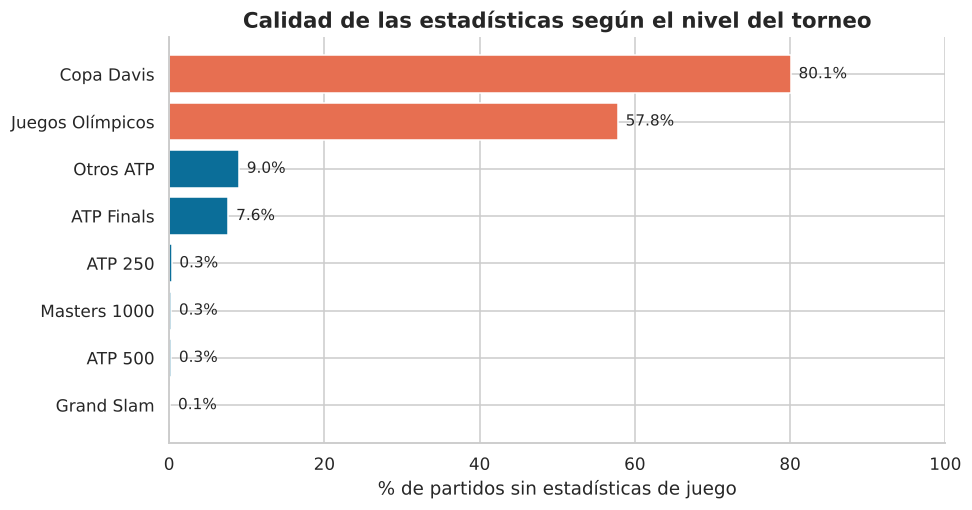

In [ ]:
datos = resumen_calidad.copy()
datos.index = [NOMBRES_NIVEL.get(str(i), str(i)) for i in datos.index]
datos = datos.sort_values('Porcentaje de Nulos (%)')
colores = [NARANJA if n in ('Copa Davis', 'Juegos Olímpicos') else AZUL for n in datos.index]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(datos.index, datos['Porcentaje de Nulos (%)'], color=colores)
for y, v in enumerate(datos['Porcentaje de Nulos (%)']):
    ax.text(v + 1, y, f'{v:.1f}%', va='center', fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel('% de partidos sin estadísticas de juego')
ax.set_title('Calidad de las estadísticas según el nivel del torneo')
plt.tight_layout()
guardar_figura(fig, 'fig02_nulos_por_nivel')
plt.show()

### 3.1 Calidad de datos: antes y después del tratamiento

Revisamos cuatro aspectos: valores nulos, filas duplicadas, valores atípicos (outliers) y tipos de datos. La tabla resume el estado antes y después del tratamiento.

| Métrica | Antes del tratamiento | Después del tratamiento |
|---|---|---|
| Partidos (filas) | 78.091 | 70.311 |
| Filas duplicadas | 0 | 0 |
| Valores nulos en partidos | 378.735 | 0 |
| Columnas en partidos | 50 | 59 |
| Jugadores (filas) | 7.643 | 2.733 |
| Valores nulos en jugadores | 38.254 | 109 |

No encontramos filas duplicadas exactas, así que no hubo que eliminar registros por ese motivo. Los nulos de partidos bajan de 378.735 a cero. En la tabla de jugadores quedan 109 nulos, que no afectan al dataset de partidos.

In [ ]:
resumen_pre_post = pd.DataFrame({
    'Antes del tratamiento': [len(df_torneos), int(df_torneos.duplicated().sum()), int(df_torneos.isna().sum().sum()),
                              df_torneos.shape[1], len(df_players), int(df_players.isna().sum().sum())],
    'Después del tratamiento': [len(df_torneos_clean), int(df_torneos_clean.duplicated().sum()),
                                int(df_torneos_clean.isna().sum().sum()), df_torneos_clean.shape[1],
                                len(df_players_clean), int(df_players_clean.isna().sum().sum())],
}, index=['Partidos (filas)', 'Filas duplicadas', 'Valores nulos (total)', 'Columnas en partidos',
          'Jugadores (filas)', 'Valores nulos en jugadores'])
print('Calidad de datos: antes y después del tratamiento')
display(resumen_pre_post)

Calidad de datos: antes y después del tratamiento
                            Antes del tratamiento  Después del tratamiento
Partidos (filas)                            78091                    70311
Filas duplicadas                                0                        0
Valores nulos (total)                      378735                        0
Columnas en partidos                           50                       59
Jugadores (filas)                            7643                     2733
Valores nulos en jugadores                  38254                      109


Figura guardada en: figuras_storytelling/fig11_pre_post_outliers.png


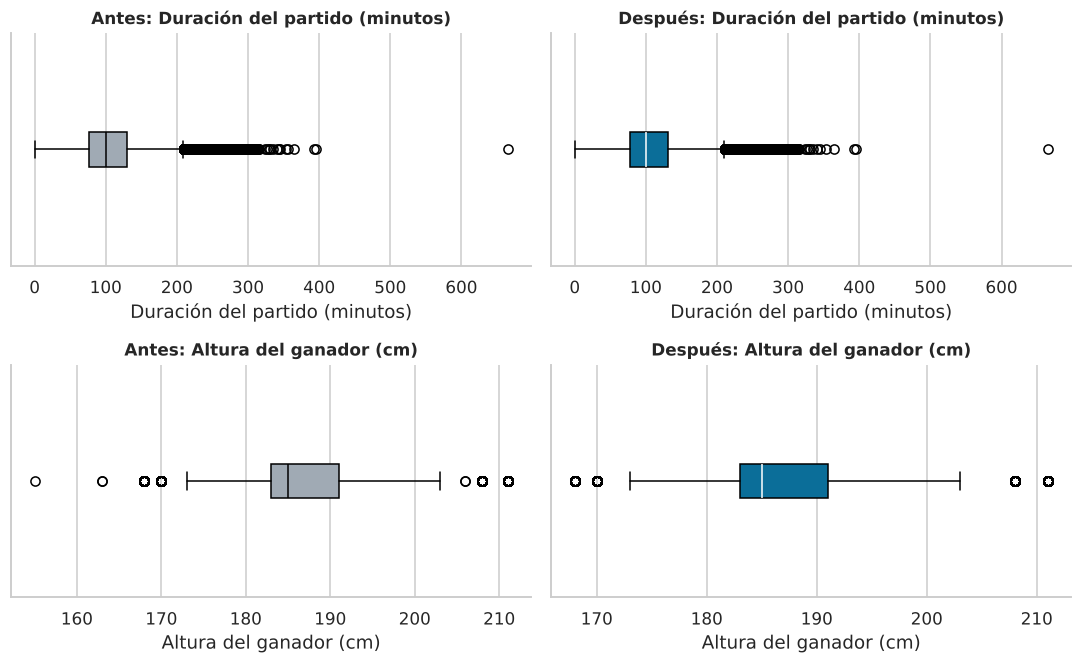

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.2))
variables_bp = [('minutes', 'Duración del partido (minutos)'), ('winner_ht', 'Altura del ganador (cm)')]
for fila, (columna, etiqueta) in enumerate(variables_bp):
    axes[fila, 0].boxplot(df_torneos[columna].dropna(), vert=False, patch_artist=True,
                          boxprops=dict(facecolor=GRIS), medianprops=dict(color='black'))
    axes[fila, 0].set_title('Antes: ' + etiqueta, fontsize=11)
    axes[fila, 1].boxplot(df_torneos_clean[columna].dropna(), vert=False, patch_artist=True,
                          boxprops=dict(facecolor=AZUL), medianprops=dict(color='white'))
    axes[fila, 1].set_title('Después: ' + etiqueta, fontsize=11)
    for ax in axes[fila]:
        ax.set_yticks([])
        ax.set_xlabel(etiqueta)
plt.tight_layout()
guardar_figura(fig, 'fig11_pre_post_outliers')
plt.show()

Los valores atípicos más visibles son partidos de duración excepcional y alturas poco habituales. No los eliminamos todos, porque un partido largo es un hecho real. En cambio, los tratamos con medianas, que no se mueven con los extremos.

### 3.2 Transformación: columnas nuevas y reglas de negocio

- **Estandarización.** Unificamos nombres de columnas (por ejemplo, altura pasa a llamarse ht), convertimos las fechas a formato fecha y los identificadores a texto. En la tabla de jugadores, quien no tiene coach queda marcado como "Solo".
- **Columnas nuevas.** Sets jugados y sets y games ganados por cada jugador, a partir del marcador; edad calculada al día del torneo; un identificador cronológico de partido (match_id); y las variables de Elo, forma, saque, devolución y diferencias entre jugadores.
- **Codificación de la ronda.** Usamos one-hot encoding: cada ronda pasa a ser una columna propia, para que el modelo no suponga un orden numérico entre rondas.
- **Reglas de negocio.** Excluimos Copa Davis y Juegos Olímpicos. El ranking faltante se completa con 1.000 y los puntos faltantes con 0. Los walkovers no actualizan el Elo, porque un jugador que no compite no informa su nivel. Conservamos solo los jugadores con actividad en el período.
- **Resumen del proceso.** Partimos de 78.091 partidos y 50 columnas. Llegamos a 70.311 partidos sin nulos, con 59 columnas. El dataset de modelado tiene 83 columnas, de las cuales 73 son variables predictoras.

## 4. Evidencia: el proceso de ciencia de datos

Recorremos las etapas del proyecto: datos, ETL, elección del modelo, división del dataset, entrenamiento, métricas y, por último, el simulador.

### 4.1 Variables: qué sabe el modelo de cada jugador

El ranking ATP suma los puntos de las últimas 52 semanas. Esto castiga a un jugador que vuelve de una lesión o que juega pocos torneos, aunque sea muy bueno. Para que el modelo vea el historial completo, construimos **73 variables predictoras** agrupadas en ocho familias:

| Familia | Qué mide | Ejemplos de variables |
|---|---|---|
| Ranking ATP | Posición y puntos oficiales | rank, rank_points |
| Elo general y por superficie | Nivel real, actualizado con cada partido | elo, elo_sup |
| Forma reciente | Victorias en los últimos 10 partidos | forma_10 |
| Superficie | % de victorias en la superficie del partido | win_pct_surface |
| Saque | Efectividad de saque con media móvil exponencial | form_r_1stWon, form_r_ace |
| Devolución | Puntos ganados al resto y break points convertidos | form_r_ret_won, form_r_bp_conv |
| Historial directo | Victorias previas entre los dos jugadores | h2h |
| Físico y actividad | Edad, altura, experiencia y días sin competir | age, ht, experiencia, dias_inactivo |

Tomamos dos decisiones metodológicas clave. Primero, usamos **porcentajes** (por ejemplo, aces sobre puntos de saque) y no conteos absolutos, porque un conteo depende de cuánto duró el partido. Segundo, todas las variables se calculan **solo con partidos anteriores**, para evitar la fuga de datos (*data leakage*): las estadísticas del propio partido nunca entran al modelo.

### 4.2 Elo: el factor que más pesa

El Elo parte de 1.500 puntos y se actualiza con cada resultado: el ganador suma y el perdedor resta según cuánto se esperaba ese resultado. Una sorpresa mueve mucho el rating; un resultado esperado, muy poco. El factor de ajuste es K = 250 / (partidos + 5)^0,4, de modo que los jugadores nuevos se ajustan rápido y los veteranos se estabilizan. Los walkovers no actualizan el rating, porque un jugador que no compite no informa su nivel.

Figura guardada en: figuras_storytelling/fig03_top10_elo.png


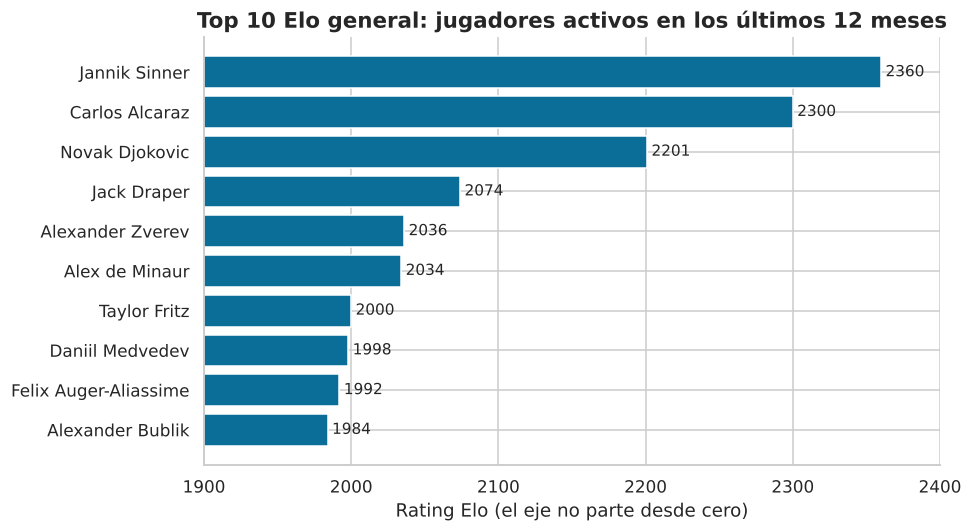

In [ ]:
datos = top_elo.sort_values('Elo')

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(datos['Jugador'], datos['Elo'], color=AZUL)
for y, v in enumerate(datos['Elo']):
    ax.text(v + 3, y, f'{v:.0f}', va='center', fontsize=10)
ax.set_xlim(1900, 2400)
ax.set_xlabel('Rating Elo (el eje no parte desde cero)')
ax.set_title('Top 10 Elo general: jugadores activos en los últimos 12 meses')
plt.tight_layout()
guardar_figura(fig, 'fig03_top10_elo')
plt.show()

Sinner (2.360) y Alcaraz (2.300) encabezan el ranking Elo con una distancia de casi 100 puntos sobre el tercero. El Elo es más fino que el ranking porque depende de *contra quién* se ganó o se perdió y no solo de cuántos puntos se acumularon.

### 4.3 División del dataset y validación

No usamos muestreo aleatorio. Con datos deportivos, un *split* aleatorio dejaría entrenar con partidos de 2023 para predecir partidos de 2010: se usaría información del futuro para predecir el pasado. Por eso entrenamos con **64.729 partidos anteriores a 2024 (92,1 %)** y evaluamos con **5.582 partidos posteriores (7,9 %)**. Dentro del entrenamiento, la búsqueda de hiperparámetros usa `TimeSeriesSplit` con 5 particiones: siempre entrena con el pasado y valida con el período siguiente.

Cada partido se predice en los dos sentidos (A contra B y B contra A) y las probabilidades se promedian, de modo que la predicción no depende de quién figura como "A". Además, el lugar del ganador se asigna al azar (semilla 42) para que el modelo no aprenda que "A siempre gana". Con esto, la clase 1 y la clase 0 quedan balanceadas (50 %).

### 4.4 Modelos y ajuste de hiperparámetros

Comparamos cuatro candidatos frente a una línea base de dominio: la regla "gana el mejor rankeado". La selección se hizo por **Log-Loss en validación cruzada temporal**, no en test, para no ajustar el modelo con la evaluación.

| Modelo | Qué aprende | Hiperparámetros probados | Elegido | Log-Loss CV |
|---|---|---|---|---|
| Regresión logística | Tendencias lineales, con regularización L2 | C ∈ {0,001; 0,01; 0,1; 1} | C = 0,01 | 0,5907 |
| Random Forest | Ensamble de árboles en paralelo (*bagging*) | max_depth ∈ {10; 14}, min_samples_leaf ∈ {20; 50} | 14 / 20 | 0,5935 |
| Gradient Boosting | Árboles secuenciales que corrigen los errores previos | learning_rate ∈ {0,03; 0,1}, max_depth ∈ {3; 5} | 0,03 / 3 | 0,5916 |
| **Ensamble (promedio)** | Promedio de las probabilidades de los tres anteriores | — | **Modelo final** | **0,5901** |

El ensamble ganó por un margen pequeño frente a la regresión logística (0,5901 contra 0,5907). Ese margen es menor que el desvío entre particiones temporales (cerca de 0,0125), así que la ventaja es real pero modesta. Lo elegimos porque cada modelo se equivoca de forma distinta y el promedio reduce ese error.

### 4.5 Teoría de los modelos elegidos

- **Regresión logística.** Modelo lineal: calcula una suma ponderada de las variables y la transforma en una probabilidad entre 0 y 1. La regularización L2 penaliza los pesos grandes. Con C = 0,01 (valor chico), el modelo es conservador y evita memorizar casos particulares.
- **Random Forest.** Entrena muchos árboles de decisión, cada uno con una muestra y un subconjunto de variables distinto, y promedia sus votos. Hiperparámetros: 150 árboles; profundidad máxima 14, que limita la complejidad de cada árbol; y mínimo de 20 partidos por hoja, para que ninguna regla dependa de un solo caso.
- **Gradient Boosting.** Entrena árboles en secuencia, donde cada árbol corrige los errores del anterior. Con una tasa de aprendizaje de 0,03, cada árbol aporta poco, lo que hace el resultado más estable. Profundidad 3 y mínimo de 100 partidos por hoja.
- **Ensamble por promedio.** Promedia las probabilidades de los tres modelos anteriores. Como se equivocan de forma distinta, el promedio reduce el error.

Los hiperparámetros se eligieron con búsqueda en grilla y validación temporal, optimizando el Log-Loss. Así, cada valor queda justificado por el desempeño en datos que el modelo no usó para entrenar.

## 5. Resultados

### 5.1 Desempeño en test

Estas son las cifras clave del análisis. Se recalculan en la celda siguiente a partir de las variables del notebook, para que cada número del texto sea reproducible.

In [ ]:
acc = df_comparativa.loc['Accuracy']
auc = df_comparativa.loc['ROC-AUC']
ll = df_comparativa.loc['Log-Loss']

fav90 = df_conf[df_conf['prob_favorito'] > 0.90]
top10 = df_conf[df_conf['top10_vs_top10']]

cifras = pd.Series({
    'Partidos de test': len(X_test),
    'Accuracy: baseline (ranking)': acc['Baseline (Ranking)'],
    'Accuracy: modelo final': acc[nombre_final],
    'ROC-AUC: baseline (ranking)': auc['Baseline (Ranking)'],
    'ROC-AUC: modelo final': auc[nombre_final],
    'Log-Loss: modelo final': ll[nombre_final],
    'Sorpresas (gana el peor rankeado)': df_eval['sorpresa'].mean(),
    'Favoritos > 90%: cantidad de partidos': len(fav90),
    'Favoritos > 90%: probabilidad predicha': fav90['prob_favorito'].mean(),
    'Favoritos > 90%: victorias reales': fav90['gano_favorito'].mean(),
    'Top 10 vs top 10: cantidad de partidos': len(top10),
    'Top 10 vs top 10: probabilidad predicha': top10['prob_favorito'].mean(),
    'Top 10 vs top 10: victorias reales': top10['gano_favorito'].mean(),
})
display(cifras.to_frame('Valor').round(4))

                                             Valor
Partidos de test                         5582.0000
Accuracy: baseline (ranking)                0.6372
Accuracy: modelo final                      0.6453
ROC-AUC: baseline (ranking)                 0.6891
ROC-AUC: modelo final                       0.7138
Log-Loss: modelo final                      0.6166
Sorpresas (gana el peor rankeado)           0.3628
Favoritos > 90%: cantidad de partidos     198.0000
Favoritos > 90%: probabilidad predicha      0.9285
Favoritos > 90%: victorias reales           0.9444
Top 10 vs top 10: cantidad de partidos    120.0000
Top 10 vs top 10: probabilidad predicha     0.6711
Top 10 vs top 10: victorias reales          0.7000


| Métrica (test 2024–2026) | Baseline (ranking) | Regresión logística | Random Forest | Gradient Boosting | **Ensamble (final)** |
|---|---|---|---|---|---|
| Accuracy | 63,7 % | 64,6 % | 64,3 % | 64,5 % | **64,6 %** |
| Precisión | 64,3 % | 65,1 % | 64,8 % | 64,9 % | 65,0 % |
| Recall | 63,5 % | 64,5 % | 64,3 % | 64,8 % | 64,7 % |
| F1-Score | 63,9 % | 64,8 % | 64,5 % | 64,9 % | 64,9 % |
| ROC-AUC | 0,689 | 0,713 | 0,712 | 0,713 | **0,714** |
| Log-Loss | — | 0,6184 | 0,6178 | 0,6177 | **0,6166** |
| Brier Score | — | 0,2155 | 0,2152 | 0,2153 | **0,2148** |

Precisión, recall y F1 casi coinciden con el accuracy. Es una consecuencia directa de la simetrización: "gana A" no significa nada en particular, así que un falso positivo y un falso negativo son el mismo error (elegir al jugador que perdió). Por eso, las métricas que importan son el accuracy, el ROC-AUC y las de calidad de probabilidad (Log-Loss y Brier).

**Nota de reproducibilidad.** Los gráficos de este documento se generaron reproduciendo el notebook con scikit-learn 1.6.1 y pandas 2.2.2. Algunas cifras cambian en décimas: el ensamble da 64,5 % de accuracy (la tabla original muestra 64,6 %) y el favorito en los partidos top 10 gana el 70,0 % (frente a 70,8 %). El texto usa las cifras del notebook original; las figuras muestran los valores de la reproducción. Las conclusiones no cambian: en ambos casos el modelo sigue siendo levemente conservador. Las diferencias provienen de redondeos de punto flotante en Gradient Boosting.

Figura guardada en: figuras_storytelling/fig04_comparacion_modelos.png


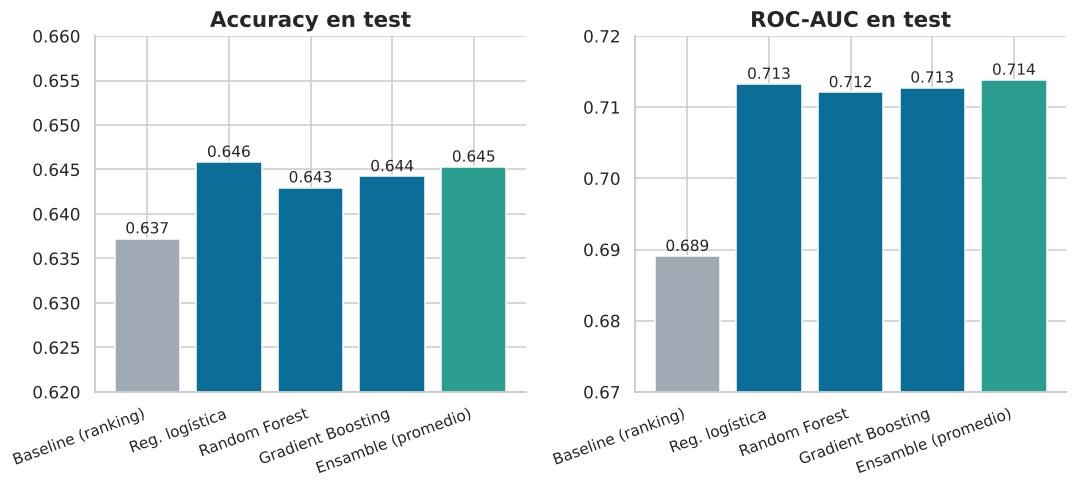

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

def etiqueta(nombre):
    return nombre.replace('Regresión Logística', 'Reg. logística').replace('Baseline (Ranking)', 'Baseline (ranking)')

def color_modelo(nombre):
    if nombre == 'Baseline (Ranking)':
        return GRIS
    return VERDE if nombre == nombre_final else AZUL

paneles = [(axes[0], acc, 'Accuracy en test', '{:.3f}', (0.62, 0.66)),
           (axes[1], auc, 'ROC-AUC en test', '{:.3f}', (0.67, 0.72))]
for ax, serie, titulo, formato, (lim_inf, lim_sup) in paneles:
    ax.bar([etiqueta(n) for n in serie.index], serie.values, color=[color_modelo(n) for n in serie.index])
    ax.set_ylim(lim_inf, lim_sup)
    ax.set_title(titulo)
    ax.tick_params(axis='x', labelsize=10)
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
    for x, v in enumerate(serie.values):
        ax.text(x, v + (lim_sup - lim_inf) * 0.015, formato.format(v), ha='center', fontsize=10)
plt.tight_layout()
guardar_figura(fig, 'fig04_comparacion_modelos')
plt.show()

El ensamble tiene el mejor ROC-AUC, el mejor Log-Loss y el mejor Brier. Pero los cuatro modelos están muy juntos. La mejora frente a la línea base (+0,9 puntos de accuracy y +0,025 de ROC-AUC) es real, aunque chica. **El algoritmo importa menos que la información que recibe**, y eso se confirma en la sección 5.3.

La siguiente curva muestra lo mismo desde otro ángulo: qué tan bien separa cada modelo a los ganadores de los perdedores en todo el rango de umbrales.

Figura guardada en: figuras_storytelling/fig05_curvas_roc.png


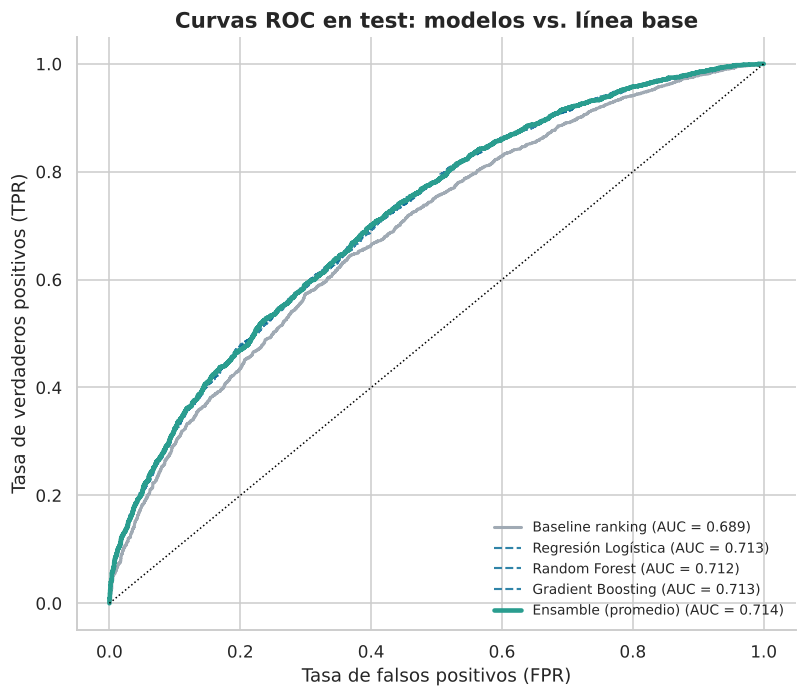

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))

fpr, tpr, _ = roc_curve(y_test, score_rank)
ax.plot(fpr, tpr, color=GRIS, lw=2,
        label=f'Baseline ranking (AUC = {roc_auc_score(y_test, score_rank):.3f})')

for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    es_final = nombre == nombre_final
    ax.plot(fpr, tpr, color=VERDE if es_final else AZUL, lw=3 if es_final else 1.4,
            ls='-' if es_final else '--', alpha=1 if es_final else 0.85,
            label=f'{nombre} (AUC = {roc_auc_score(y_test, p):.3f})')

ax.plot([0, 1], [0, 1], color='black', ls=':', lw=1)
ax.set_xlabel('Tasa de falsos positivos (FPR)')
ax.set_ylabel('Tasa de verdaderos positivos (TPR)')
ax.set_title('Curvas ROC en test: modelos vs. línea base')
ax.legend(loc='lower right', fontsize=9, frameon=False)
plt.tight_layout()
guardar_figura(fig, 'fig05_curvas_roc')
plt.show()

### 5.2 ¿Las probabilidades altas son exageradas? (H2)

Un modelo puede acertar bastante y, aun así, exagerar su confianza. Para comprobarlo agrupamos los partidos de test según la confianza del modelo en el favorito y comparamos la probabilidad predicha con la frecuencia real de victorias del favorito.

- En el tramo **90–100 %** (198 partidos), el modelo predijo 92,9 % y el favorito ganó **94,4 %** de las veces.
- En los partidos **entre dos jugadores del top 10** (120 partidos), el modelo le dio al favorito **67,1 %** en promedio, y el favorito ganó **70,8 %**.

El modelo no exagera. Si acaso, es levemente conservador. **H2 se sostiene.**

Figura guardada en: figuras_storytelling/fig06_calibracion_confianza.png


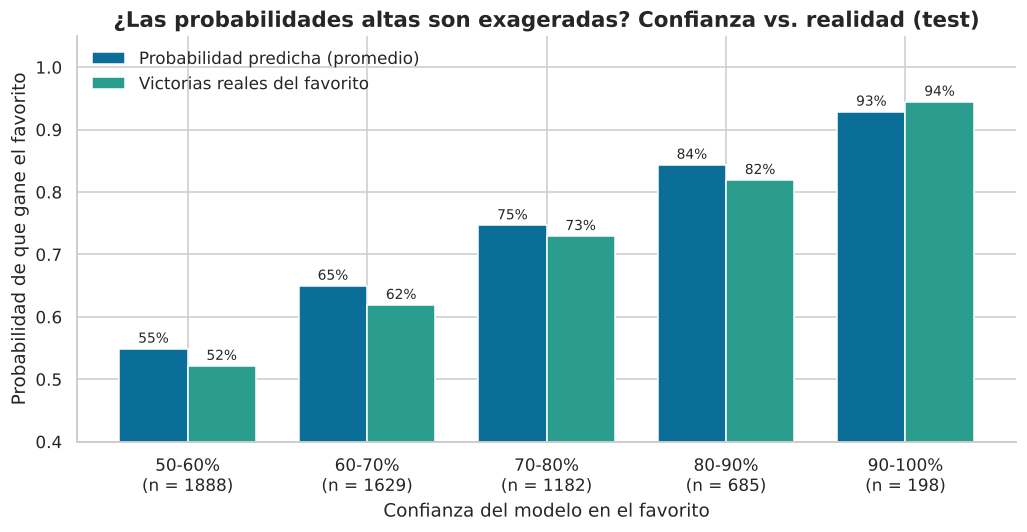

In [ ]:
fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(tabla_confianza))
ancho = 0.38
ax.bar(x - ancho / 2, tabla_confianza['prob_predicha_media'], ancho, color=AZUL,
       label='Probabilidad predicha (promedio)')
ax.bar(x + ancho / 2, tabla_confianza['victorias_reales_favorito'], ancho, color=VERDE,
       label='Victorias reales del favorito')

ax.set_xticks(x)
ax.set_xticklabels([f'{c}\n(n = {n})' for c, n in
                    zip(tabla_confianza.index.astype(str), tabla_confianza['partidos'])])
for xi, (p, r) in enumerate(zip(tabla_confianza['prob_predicha_media'],
                                tabla_confianza['victorias_reales_favorito'])):
    ax.text(xi - ancho / 2, p + 0.01, f'{p:.0%}', ha='center', fontsize=9)
    ax.text(xi + ancho / 2, r + 0.01, f'{r:.0%}', ha='center', fontsize=9)

ax.set_ylim(0.4, 1.05)
ax.set_ylabel('Probabilidad de que gane el favorito')
ax.set_xlabel('Confianza del modelo en el favorito')
ax.set_title('¿Las probabilidades altas son exageradas? Confianza vs. realidad (test)')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
guardar_figura(fig, 'fig06_calibracion_confianza')
plt.show()

La matriz de confusión muestra cómo se reparten los aciertos y los errores. Como el orden de A y B es aleatorio, el eje "gana A / gana B" no tiene un significado especial: lo que importa es la diagonal, es decir, cuántas veces el modelo eligió al jugador que efectivamente ganó.

Figura guardada en: figuras_storytelling/fig10_matriz_confusion.png


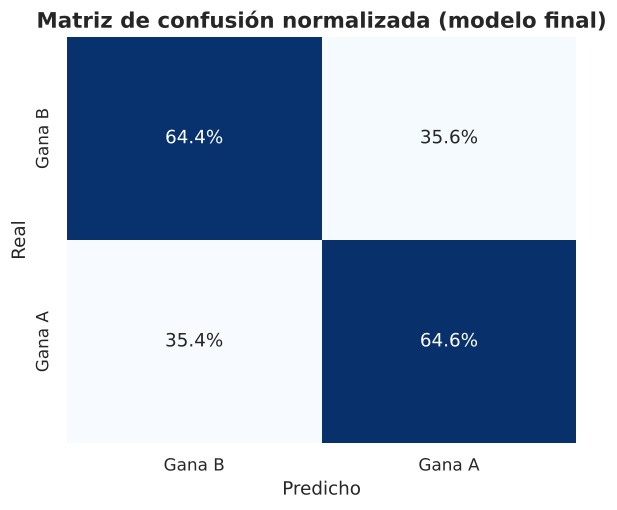

In [ ]:
cm = confusion_matrix(y_test, y_pred_final, normalize='true')

fig, ax = plt.subplots(figsize=(5.5, 4.8))
sns.heatmap(cm, annot=True, fmt='.1%', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Gana B', 'Gana A'], yticklabels=['Gana B', 'Gana A'])
ax.set_xlabel('Predicho')
ax.set_ylabel('Real')
ax.set_title('Matriz de confusión normalizada (modelo final)')
plt.tight_layout()
guardar_figura(fig, 'fig10_matriz_confusion')
plt.show()

### 5.3 Historial vs. ranking: ¿el modelo solo copia el ranking? (H1)

Para responder si el modelo realmente usa el historial, o si se apoya solo en la diferencia de ranking, entrenamos tres versiones con los mismos hiperparámetros: solo ranking (9 variables), solo historial sin ranking (65 variables) y completo (73 variables).

Sin ver el ranking para nada, el modelo obtiene **64,6 % de accuracy** y ROC-AUC 0,711. Eso es prácticamente lo mismo que el modelo completo (64,7 %; 0,713) y claramente mejor que el ranking solo (63,3 %; 0,690). **H1 se confirma**: el historial contiene la información relevante, y el ranking es un resumen parcial de él.

Figura guardada en: figuras_storytelling/fig07_ablacion.png


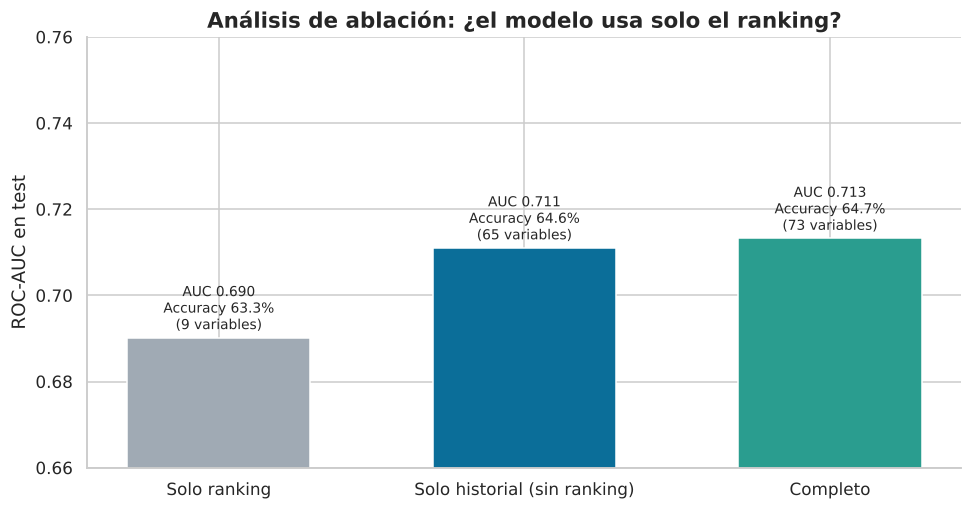

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.8))
etiquetas = df_ablacion.index.tolist()
colores_ab = [GRIS, AZUL, VERDE]
ax.bar(etiquetas, df_ablacion['ROC-AUC'], color=colores_ab[:len(etiquetas)], width=0.6)

for i, (auc_v, acc_v, n_var) in enumerate(zip(df_ablacion['ROC-AUC'], df_ablacion['Accuracy'],
                                             df_ablacion['N° variables'])):
    ax.text(i, auc_v + 0.002, f'AUC {auc_v:.3f}\nAccuracy {acc_v:.1%}\n({n_var} variables)',
            ha='center', fontsize=9)

ax.set_ylim(0.66, 0.76)
ax.set_ylabel('ROC-AUC en test')
ax.set_title('Análisis de ablación: ¿el modelo usa solo el ranking?')
plt.tight_layout()
guardar_figura(fig, 'fig07_ablacion')
plt.show()

### 5.4 ¿Qué pesa más? Importancia por familias de variables

Medimos la importancia con **permutación agrupada**: desordenamos a la vez todas las variables de una familia y medimos cuánto cae el ROC-AUC. Agrupar evita un problema clásico. El Elo y los puntos de ranking están muy correlacionados, y si se desordena una sola variable, la otra compensa y ambas parecen poco importantes.

- **Elo** (general y por superficie): cae 0,066 de ROC-AUC, casi cuatro veces lo que cae el **ranking ATP** (0,018).
- Le siguen el **saque reciente** (0,010) y el bloque **físico y de actividad** (0,007).
- La **forma de los últimos 10 partidos** (0,0001) y el **historial directo** (0,0006) casi no aportan. El modelo ya tiene medidas de forma más finas, como las medias móviles de saque y devolución, y la racha simple suma poco.

Figura guardada en: figuras_storytelling/fig08_importancia_familias.png


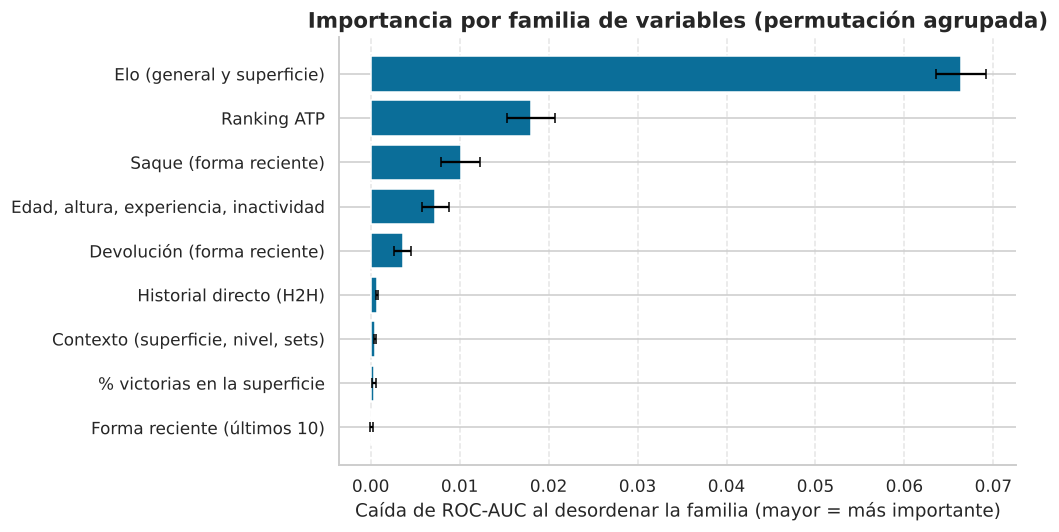

In [ ]:
datos = df_imp.sort_values('Caída de ROC-AUC')
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.barh(datos.index, datos['Caída de ROC-AUC'], xerr=datos['Desvío'],
        color=AZUL, ecolor='black', capsize=3)
ax.set_xlabel('Caída de ROC-AUC al desordenar la familia (mayor = más importante)')
ax.set_title('Importancia por familia de variables (permutación agrupada)')
ax.grid(axis='x', ls='--', alpha=0.5)
plt.tight_layout()
guardar_figura(fig, 'fig08_importancia_familias')
plt.show()

### 5.5 Patrones y tendencias: dónde acierta y dónde falla

Comparamos el modelo con la línea base del ranking en tres ejes: superficie, nivel del torneo y diferencia de ranking entre los jugadores. El número sobre cada barra verde indica la diferencia en puntos porcentuales frente al ranking.

Figura guardada en: figuras_storytelling/fig09_accuracy_por_contexto.png


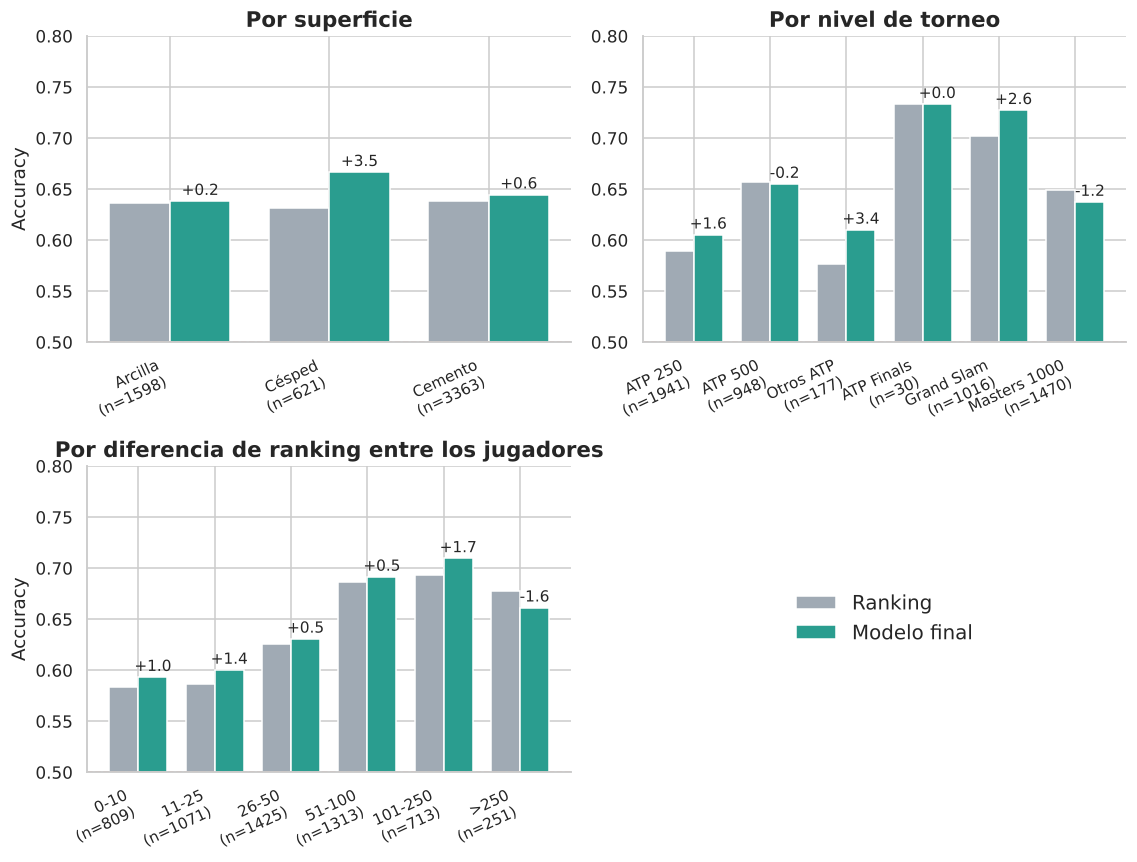

In [ ]:
def panel_contexto(ax, tabla, titulo, renombrar=None):
    t = tabla[['accuracy_ranking', 'accuracy_modelo', 'partidos']].copy()
    if renombrar:
        t.index = [renombrar.get(str(i), str(i)) for i in t.index]
    etiquetas = [f'{i}\n(n={p})' for i, p in zip(t.index, t['partidos'])]
    x = np.arange(len(t))
    ancho = 0.38
    ax.bar(x - ancho / 2, t['accuracy_ranking'], ancho, color=GRIS, label='Ranking')
    ax.bar(x + ancho / 2, t['accuracy_modelo'], ancho, color=VERDE, label='Modelo final')
    ax.set_xticks(x)
    ax.set_xticklabels(etiquetas, fontsize=10)
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    ax.axhline(0.5, color=NARANJA, ls='--', lw=1)
    ax.set_ylim(0.5, 0.8)
    ax.set_title(titulo)
    for xi, (r, m) in enumerate(zip(t['accuracy_ranking'], t['accuracy_modelo'])):
        ax.text(xi + ancho / 2, m + 0.006, f'{(m - r) * 100:+.1f}', ha='center', fontsize=10)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 8))
panel_contexto(axes[0, 0], tabla_superficie, 'Por superficie',
               {'Clay': 'Arcilla', 'Grass': 'Césped', 'Hard': 'Cemento'})
panel_contexto(axes[0, 1], tabla_nivel, 'Por nivel de torneo', NOMBRES_NIVEL)
panel_contexto(axes[1, 0], tabla_dif_rank, 'Por diferencia de ranking entre los jugadores')
axes[0, 0].set_ylabel('Accuracy')
axes[1, 0].set_ylabel('Accuracy')
for ax in [axes[0, 1], axes[1, 1]]:
    ax.set_ylabel('')
manejadores, nombres = axes[0, 0].get_legend_handles_labels()
axes[1, 1].axis('off')
axes[1, 1].legend(manejadores, nombres, loc='center', fontsize=13, frameon=False)
plt.tight_layout()
guardar_figura(fig, 'fig09_accuracy_por_contexto')
plt.show()

Estos patrones matizan el resultado general:

- **Césped es donde el modelo más mejora al ranking** (66,5 % frente a 63,1 %, +3,4 puntos). En arcilla la mejora es casi nula (+0,3). Esto respalda H3: la superficie cambia cuánto aporta el historial.
- **En Grand Slam (+2,6) y en ATP 250 (+1,7) el modelo supera al ranking.** En **Masters 1000 el ranking es mejor** (−1,1). Una hipótesis para explorar en otro trabajo es que los Masters reúnen rivales de nivel más parejo, donde el historial aporta menos. No la pusimos a prueba.
- **Con diferencias de ranking muy grandes (más de 250 puestos), el ranking gana** (67,7 % frente a 66,1 %). Cuando el desnivel es enorme, el ranking ya alcanza. El modelo marca la diferencia en los partidos parejos y medios.
- **En el 36,3 % de los partidos de test ganó el peor rankeado.** Ese es el límite de cualquier predicción hecha antes del partido. Algunos niveles, como ATP Finals con 30 partidos, tienen muestras muy chicas y deben leerse con cautela.

### 5.6 Ejemplo de uso: un partido y un torneo

**Partido.** Holger Rune (11° del ranking, Elo 1.914) enfrenta a Valentin Vacherot (32°, Elo 1.898) sobre arcilla, al mejor de 3 sets. El modelo le asigna **75,5 %** a Rune. El ranking explica poco de esa diferencia. Lo que pesa es el Elo sobre arcilla: **1.917 para Rune y 1.448 para Vacherot**. Rune ganó el 63 % de sus partidos en esa superficie (89 partidos) y Vacherot, el 14 % (7 partidos). En la explicación del modelo, el Elo (general y por superficie) aporta +15,7 puntos de probabilidad, la devolución reciente +3,0 y el ranking +2,9.

**Torneo.** Simulamos dos cuadros sobre arcilla, con formato de Grand Slam. En el de 8 jugadores estrella (al mejor de 5 sets) el campeón simulado es **Carlos Alcaraz**. En el de 32 jugadores activos, elegidos al azar con semilla fija, el campeón simulado es **Casper Ruud**. Cada ronda muestra la probabilidad del ganador y las variables que lo favorecieron.

Una simulación muestra un escenario posible, no una predicción garantizada: un único resultado, con la aleatoriedad de cada partido. Para estimar la probabilidad de campeón de cada jugador habría que simular miles de cuadros, algo que queda como trabajo futuro.

## 6. Decisiones técnicas clave

Cada decisión responde a un problema concreto de los datos o del diseño experimental. La tabla resume las más importantes.

| Etapa | Decisión | Justificación |
|---|---|---|
| ETL | Excluir Copa Davis y Juegos Olímpicos | 80 % y 58 % de partidos sin estadísticas; formato distinto al circuito ATP |
| ETL | Ranking faltante = 1.000; puntos faltantes = 0 | Ubica a los jugadores sin posición en el extremo, sin inventar un puesto |
| ETL | Altura faltante = mediana; edad = calculada desde la fecha de nacimiento | Distribución simétrica (la mediana no altera la tendencia); la fecha es más precisa |
| ETL | Minutos faltantes = mediana por formato (`best_of`) | Distribución con cola larga a la derecha; la media estaría sesgada |
| ETL | Estadísticas faltantes = mediana por superficie | Evita mezclar superficies con rendimientos muy distintos |
| Variables | Porcentajes y medias móviles exponenciales (ventana de 20 partidos) | Un conteo depende de la duración del partido; la media móvil refleja el nivel actual |
| Variables | Solo información previa al partido | Evita *data leakage*: aces, minutos y games del propio partido nunca entran |
| Variables | Elo con K = 250 / (n + 5)^0,4; walkovers sin actualización | Ajuste rápido para jugadores nuevos y estable para veteranos; un W/O no informa nivel |
| Datos | Orden cronológico: fecha, torneo, ronda, número de partido | Todos los partidos de un torneo comparten la fecha de inicio; sin este orden, una final quedaría antes que partidos previos |
| Partición | Corte temporal el 1-ene-2024, sin *shuffle* | Replica el uso real: predecir con datos del pasado |
| Target | Simetrización aleatoria (Bernoulli 0,5, semilla 42) | Evita que el modelo aprenda que "A siempre gana" |
| Validación | `TimeSeriesSplit` de 5 particiones; selección por Log-Loss | Respeta el orden temporal y premia probabilidades bien calibradas |
| Algoritmos | Gradient Boosting con `HistGradientBoostingClassifier` (scikit-learn) | Sin dependencias externas; es el mismo tipo de modelo que XGBoost, planteado en la Entrega 1 |
| Evaluación | Accuracy, ROC-AUC, Log-Loss y Brier como métricas principales | Con el target simetrizado, precisión, recall y F1 repiten el accuracy |

## 7. Desenlace: conclusiones y recomendaciones

### 7.1 Conclusiones

1. **El historial supera al ranking.** El modelo final acierta 64,6 % de los partidos de test, frente a 63,7 % del ranking, con un ROC-AUC de 0,714 frente a 0,689. Sin ver el ranking, el rendimiento es casi el mismo (H1).
2. **El Elo es el factor más importante.** Su peso en el modelo es casi cuatro veces el del ranking oficial. El rating que depende de *contra quién* se ganó resume mejor el nivel real de un jugador.
3. **Las probabilidades son confiables.** Cuando el modelo asigna más de 90 %, el favorito gana 94 % de las veces. Entre jugadores del top 10, el modelo es levemente conservador (H2).
4. **El azar pone un techo.** En más de uno de cada tres partidos (36,3 %) gana el peor rankeado. Ningún modelo previo al partido elimina esa incertidumbre, y 64–65 % de aciertos es un resultado razonable dentro de ese límite.
5. **El contexto importa.** El modelo aporta más en césped y en Grand Slam, y el ranking se defiende en Masters 1000 y en desniveles extremos (H3).

### 7.2 Recomendaciones

- **Para analistas y medios:** usar las probabilidades como punto de partida y leer la explicación por familias ("¿por qué gana?") en lugar de quedarse con una cifra. Interpretar con cuidado los contextos con poca muestra.
- **Para equipos técnicos:** el Elo por superficie y la devolución reciente son los indicadores más útiles para preparar un rival, como en el caso de Vacherot sobre arcilla.
- **Para próximas iteraciones del proyecto:**
  - Incorporar datos que hoy no tenemos: lesiones, cansancio por partidos recientes y cuotas de mercado, que resumen información pública antes del partido.
  - Entrenar modelos separados por nivel de torneo, en particular para Masters 1000, donde el ranking hoy es más fuerte.
  - Simular miles de cuadros para estimar probabilidades de campeón, en lugar de un único escenario.
  - Modelar la evolución del rendimiento de cada jugador a lo largo del tiempo, tal como planteamos en la Entrega 1, y que todavía no desarrollamos.
- **Advertencia:** no recomendamos usar este modelo para apostar. La ventaja sobre el ranking es pequeña y no la validamos contra cuotas reales.

### 7.3 Qué obtienen al contratar nuestra idea

| Quién | Qué obtiene | Evidencia en el trabajo |
|---|---|---|
| Medios y analistas | Probabilidades con explicación por factor, no solo un favorito | Con 90 % de confianza, el favorito gana el 94 % |
| Equipos técnicos | Elo por superficie y devolución reciente para preparar un rival | Caso Rune–Vacherot sobre arcilla (sección 5.6) |
| Equipo de cátedra (Product Owners) | Un ciclo completo de Ciencia de Datos, reproducible y documentado | Notebook con ETL, modelos y storytelling |
| Próxima iteración | Una hoja de ruta concreta: lesiones, cuotas y evolución por jugador | Límites identificados en la sección 8 |

**Nuestra propuesta:** tomar esta idea como base de la próxima iteración, incorporando los datos que hoy no tenemos.

## Lo que aprendimos en la materia

- Un proyecto de datos es un ciclo: la pregunta define los datos, los datos definen el modelo, y el modelo solo sirve si se comunica.
- La calidad va antes que el modelo: un 80 % de nulos en un nivel de torneo cambió una decisión de exclusión.
- Con datos temporales el orden importa: un reparto aleatorio habría filtrado el futuro al entrenamiento.
- La métrica depende del problema: para probabilidades, el Log-Loss vale más que el accuracy.
- Scrum en la práctica: roles claros y sprints alineados con cada entrega permitieron avanzar en paralelo.
- Storytelling: primero el beneficio, después la evidencia, y un mensaje por gráfico.

## 8. Limitaciones y trabajo futuro

- **Información faltante.** El modelo no conoce lesiones, clima, motivación ni cuotas de mercado.
- **Evolución temporal sin desarrollar.** La Entrega 1 proponía modelar el rendimiento de cada jugador a lo largo de su carrera. El análisis actual no lo incluye.
- **Algoritmos.** Usamos regresión logística, Random Forest y Gradient Boosting (sin XGBoost). Las diferencias entre modelos son pequeñas, así que el resultado depende más de las variables que del algoritmo.
- **Simulador.** Cada torneo se simula una sola vez. Además, el cuadro de 32 jugadores usa formato de 3 sets para un Grand Slam, mientras que el de 8 usa 5. Por eso lo presentamos como ilustrativo.
- **Muestras chicas.** Algunos niveles tienen pocos partidos en test (ATP Finals, con 30). Sus resultados son orientativos.
- **Métricas.** Con el target simetrizado, precisión, recall y F1 aportan poco. La evaluación se apoya en accuracy, ROC-AUC y calidad de probabilidad.
- **Tiempos de cómputo.** No medimos el tiempo de entrenamiento ni su consumo energético.
- **Reproducibilidad.** Pequeñas diferencias de versiones de librerías cambian algunas cifras en décimas (ver sección 5.1). Conviene verificar las cifras clave en el entorno del equipo.

## 9. Equipo y roles

El equipo trabajó con la estructura Scrum definida en la Entrega 1. Los roles se mantuvieron durante todo el ciclo:

| Rol | Integrante | Responsabilidad principal |
|---|---|---|
| Scrum Master | Angonese, Juan Pablo | Ritmo de entregas, ceremonias, tableros y documentación |
| Ingeniero de Datos | Ceballos Pratto, Agustín José | Consistencia entre fuentes, limpieza y parseo de datos |
| Ingeniero de Datos | Wendler, Juan José | Consistencia entre fuentes, limpieza y parseo de datos |
| Data Scientist | Ghibaudo, Alan Yair | Diseño, ajuste y evaluación de los modelos predictivos |
| Data Analyst | Scrosati, Emanuel Genaro | Análisis exploratorio, tendencias y visualizaciones |
| Data Analyst | Villegas, Genaro | Análisis exploratorio, tendencias y visualizaciones |

## 10. Pregunta final para la audiencia

Si el Elo ya captura el nivel de un jugador, ¿qué información tendría que sumarse para superar de forma clara el 65 % de aciertos? ¿Lesiones, cuotas de mercado o datos de cada punto en tiempo real?

## Referencias

- Tennismylife. (s.f.). *TML-Database* [Base de datos]. GitHub. https://github.com/Tennismylife/TML-Database
- Sackmann, J. (s.f.). *tennis_atp* [Repositorio de datos]. GitHub. https://github.com/JeffSackmann/tennis_atp
- Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Cátedra Ciencia de Datos. (2026). *Materiales y notas de clase*. Universidad Tecnológica Nacional, Facultad Regional Córdoba.